# **1. Analisis Exploratorio por tablas**

El primer paso, antes de cualquier analisis, es cargar las librerias y funciones que se usaran para el mismo analisis.

In [170]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

import sys

sys.path.append("../src")

from edafuncs import (
    analizar_tabla,
    heatmap_nulos,
    histogramas,
    boxplots,
    correlaciones
)

from edaload import cargar_csv, cargar_parquet

## 1.1  person.csv

### **1.1.1 Calidad de person.csv**

El archivo person.csv, se define de la siguiente manera:

- person_id: Identificador único anonimizado de cada paciente.
- gender_concept_id: Identificador estandarizado del sexo del paciente.
- year_of_birth: Año de nacimiento del paciente.
- race_concept_id: Identificador estandarizado asociado al grupo racial del paciente.
- ethnicity_concept_id: Identificador estandarizado asociado a la etnia del paciente.

In [82]:
person = cargar_csv(
    "person.csv"
)

In [83]:
analizar_tabla(person, "person")

TABLA: person

Filas: 912,205
Columnas: 5
Memoria: 34.80 MB

Duplicados: 0

Top faltantes:


,nulos,pct_nulos
person_id,0,0.0
gender_concept_id,0,0.0
year_of_birth,0,0.0
race_concept_id,0,0.0
ethnicity_concept_id,0,0.0



Resumen estadístico:


,count,mean,std,min,25%,50%,75%,max
person_id,912205.0,4.561030e+05,263331.045491,1.0,228052.0,456103.0,684154.0,912205.0
gender_concept_id,912205.0,8.519063e+03,102.079661,0.0,8507.0,8532.0,8532.0,8532.0
year_of_birth,912205.0,1.987560e+03,29.420671,1.0,1973.0,1992.0,2005.0,2026.0
race_concept_id,912205.0,4.185411e+02,1850.998109,0.0,0.0,0.0,0.0,8657.0
ethnicity_concept_id,912205.0,3.800356e+07,0.047525,38003563.0,38003563.0,38003563.0,38003563.0,38003564.0


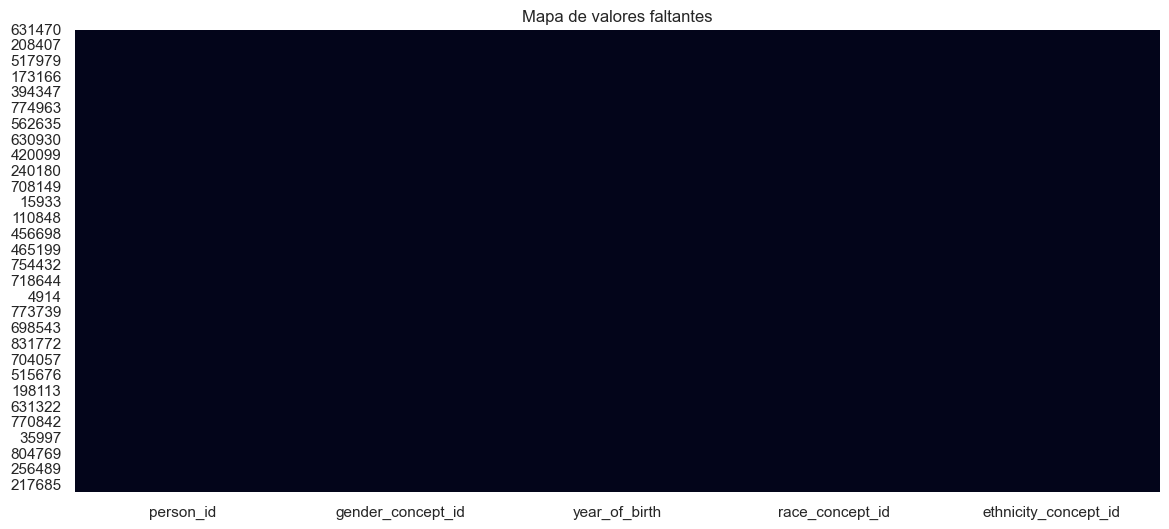

In [84]:
heatmap_nulos(person)

En este caso, para la tabla **person.csv**, no presenta ni datos nulos o duplicados, lo que significa que lo siguiente seria realizar el analisis estadistico para comprobar su distribucion.

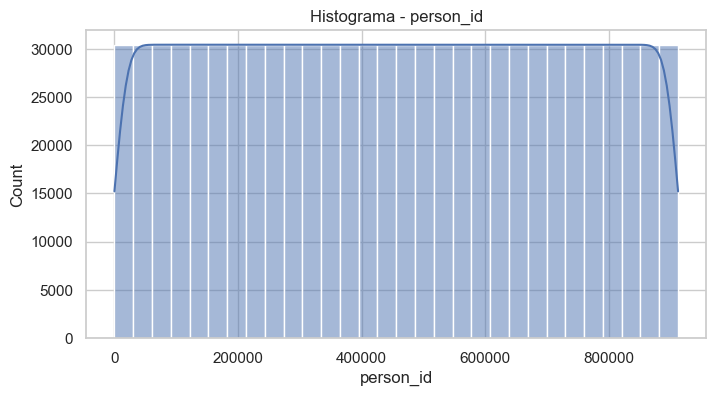

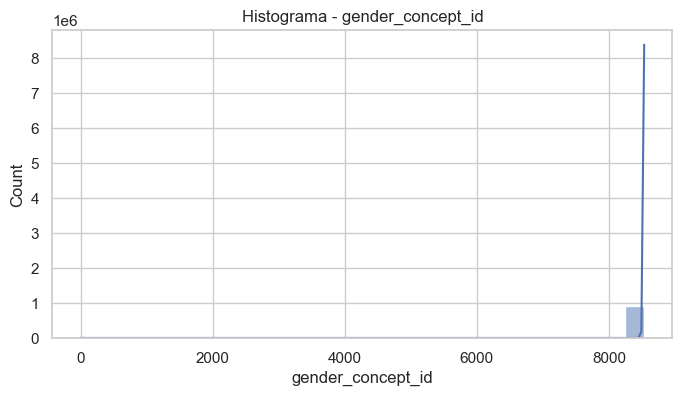

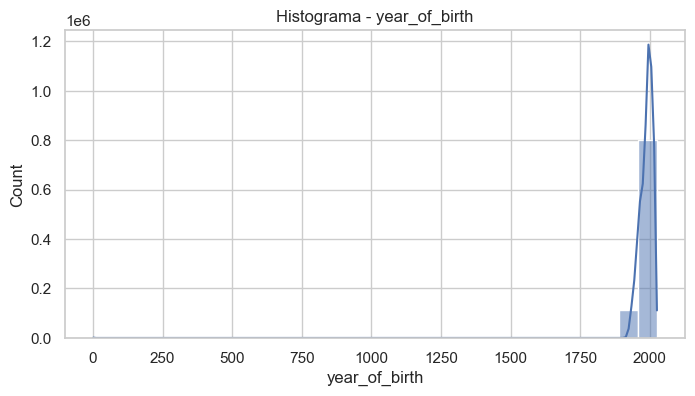

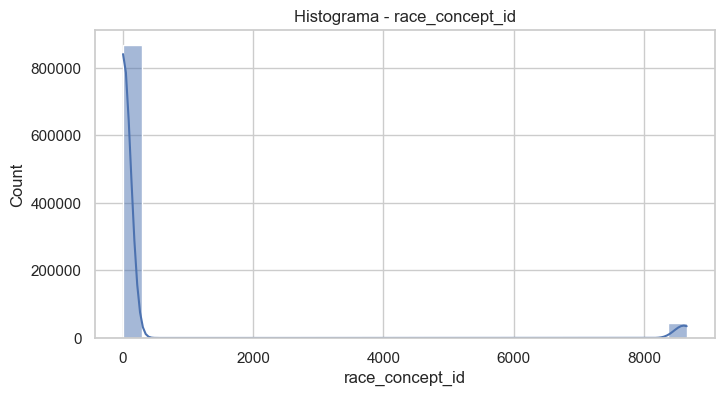

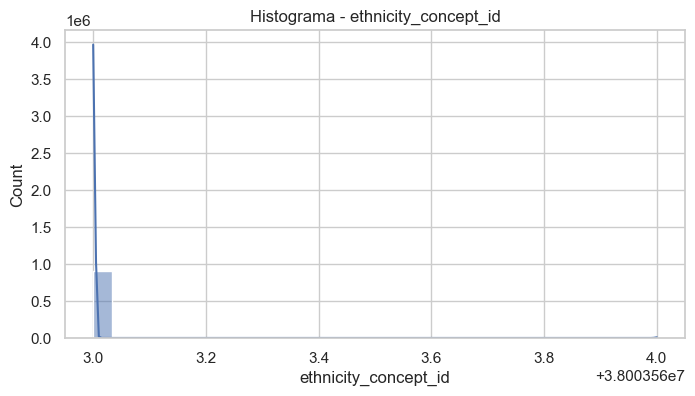

In [85]:
histogramas(person)

Por el momento, los histogramas representan de forma debida los datos. Gracias al diccionario de datos obtenido anteriormente, se refleja el comportamiento sin ninguna anomalia presente.

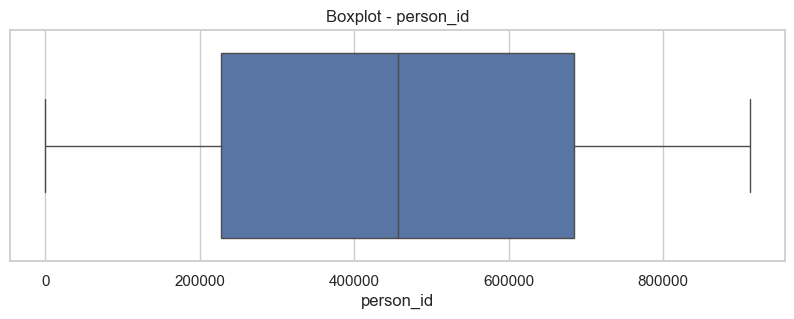

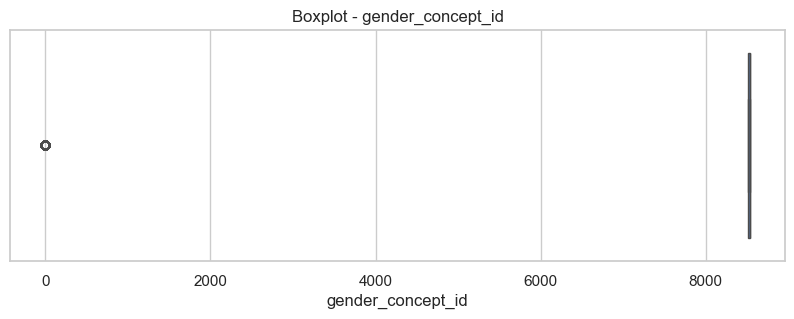

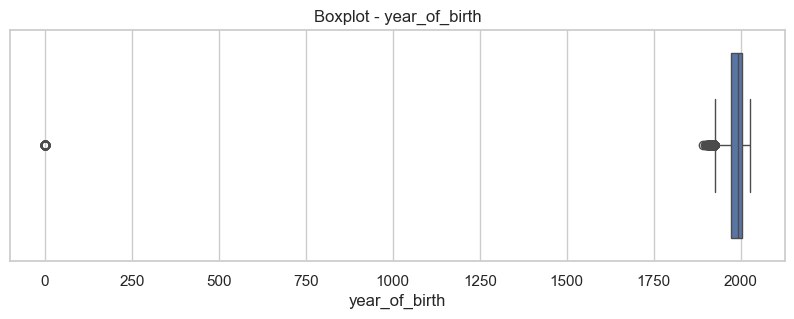

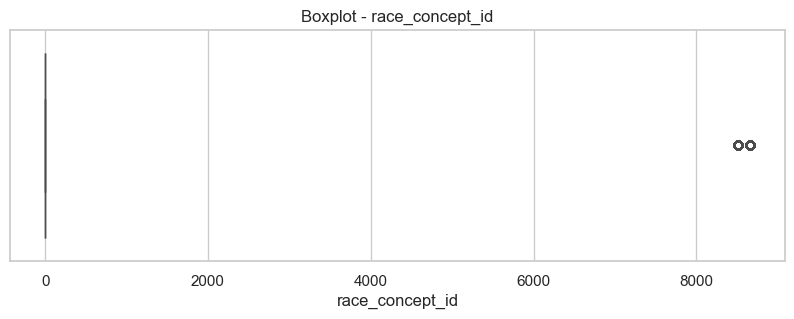

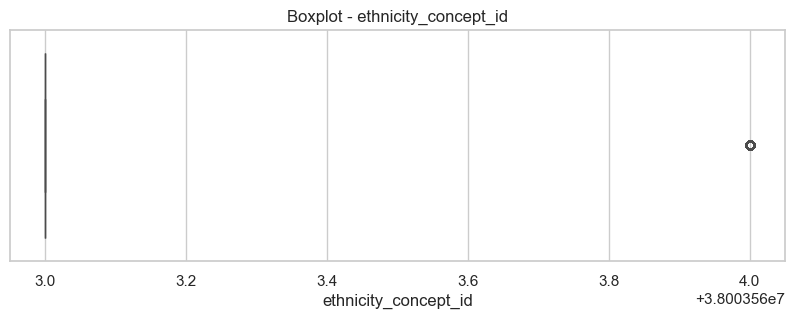

In [86]:
boxplots(person)

Lo importante a resaltar es la presencia de datos atipicos en la variable **year_of_birth**, para estos datos, se considero eliminar los registros para evitar un sesgo, especialmente gracias a su naturaleza y valor extremo dentro de la variable en si.

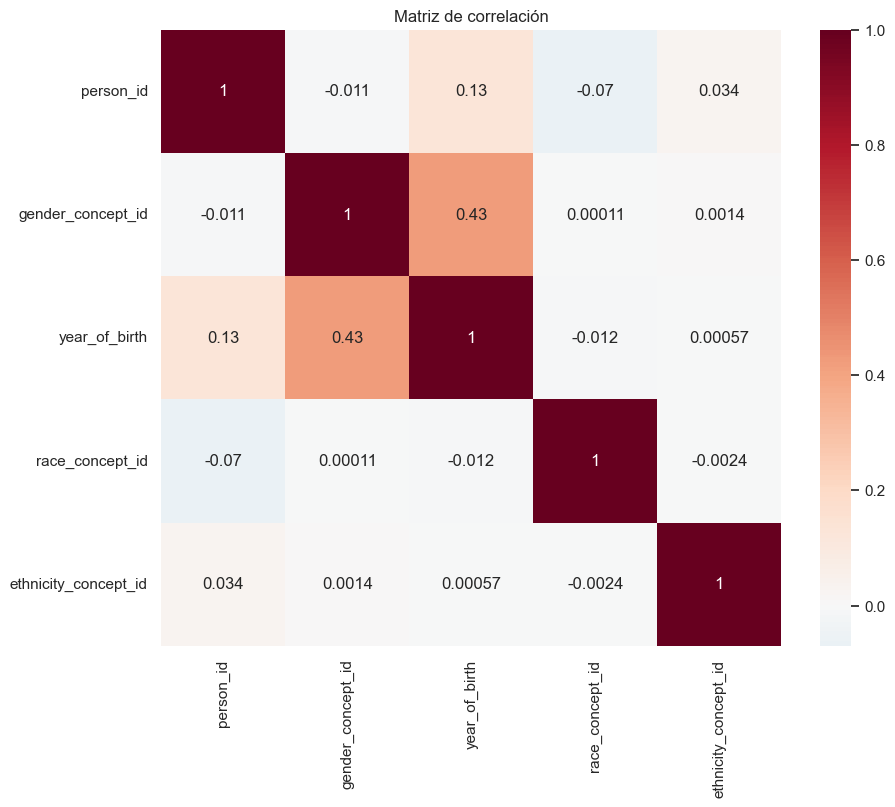

In [87]:
correlaciones(person)

### **1.1.2 Tratamiento de la variable **year_of_birth****


Se identificaron registros con valores iguales a 1 y años anteriores a 1900.

Estos valores generan edades clínicamente imposibles (>120 años), por lo que se consideran errores de calidad de datos o codificaciones especiales de valores desconocidos.

Para preservar los registros clínicos asociados y evitar pérdida de información, dichos valores serán tratados como faltantes (NaN) en las variables derivadas de edad.

In [88]:
person.loc[
    person["year_of_birth"] <= 1900,
    ["person_id", "year_of_birth"]
].head(20)

,person_id,year_of_birth
35771,756658,1
48212,769099,1
80689,801577,1
87811,808699,1
88772,809660,1
91098,811986,1
114703,835592,1
138490,859383,1
141624,862518,1
152922,873756,1


In [89]:
person.loc[
    person["year_of_birth"] < 1900
].shape

(87, 5)

In [90]:
person.loc[
    person["year_of_birth"] < 1900,
    "year_of_birth"
].value_counts().sort_index()

year_of_birth
1       85
1893     1
1898     1
Name: count, dtype: int64

In [91]:
person["year_of_birth_clean"] = (
    person["year_of_birth"]
)

person.loc[
    person["year_of_birth"] < 1900,
    "year_of_birth_clean"
] = pd.NA


In [92]:
print("Registros inválidos:",
      (person["year_of_birth_clean"] < 1900).sum())

print("Nulos creados:",
      person["year_of_birth_clean"].isna().sum())

Registros inválidos: 0
Nulos creados: 87


In [93]:
person.drop("year_of_birth", axis=1, inplace=True)

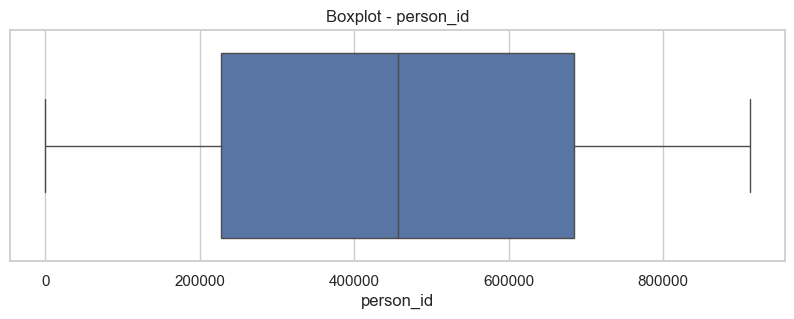

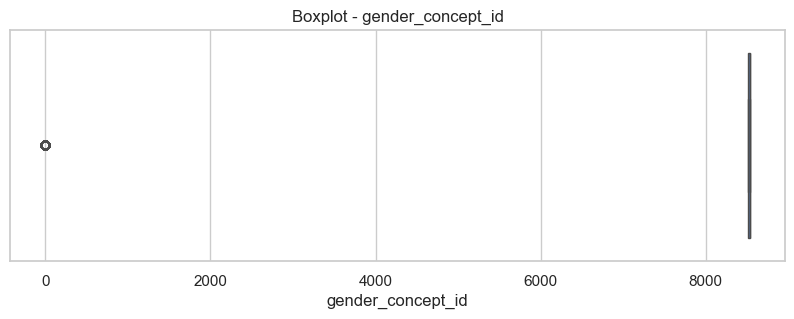

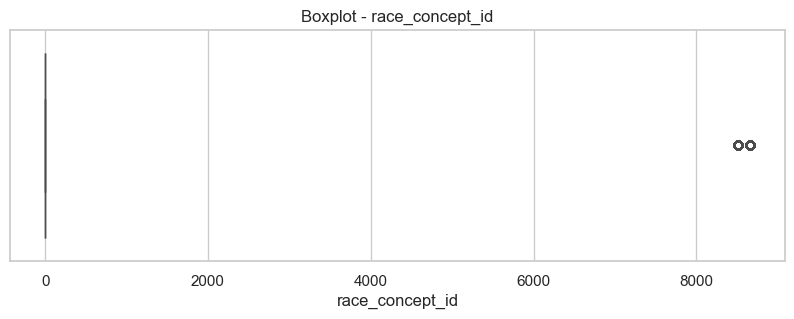

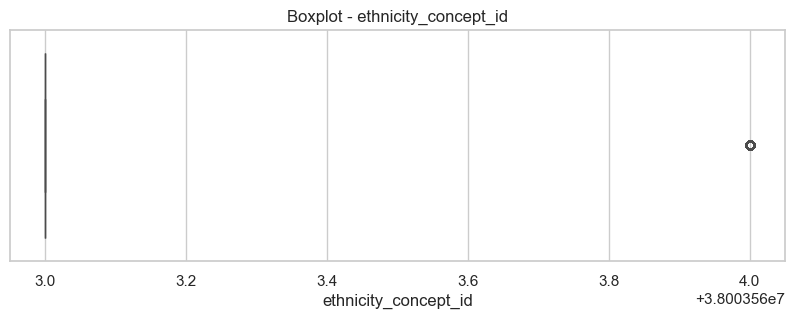

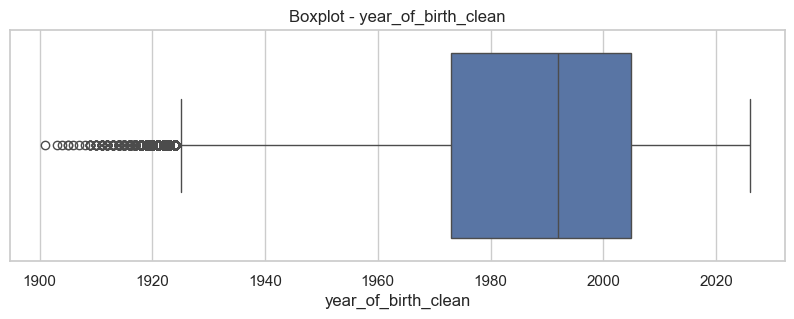

In [94]:
boxplots(person)

### **1.1.3 Exploracion y analisis de datos de person.csv**

Para esta seccion, se van a mappear aquellas variables que tienen la terminacion "concept_id", juntandolo con la tabla concept, la cual es un diccionario global para muchas variables en el dataset. Con esto, podemos entender los datos de una forma mas realista y con sentido.

In [97]:
concept = cargar_csv(
    "concept.csv"
)

concept_dict = dict(
    zip(
        concept["concept_id"],
        concept["concept_name"]
    )
)

In [98]:
person["gender"] = (
    person["gender_concept_id"]
    .map(concept_dict)
)

person["race"] = (
    person["race_concept_id"]
    .map(concept_dict)
)

person["ethnicity"] = (
    person["ethnicity_concept_id"]
    .map(concept_dict)
)

In [99]:
person[
    [
        "gender_concept_id",
        "gender",
        "race_concept_id",
        "race",
        "ethnicity_concept_id",
        "ethnicity"
    ]
].head()

,gender_concept_id,gender,race_concept_id,race,ethnicity_concept_id,ethnicity
0,8507,MALE,0,No matching concept,38003563,Hispanic or Latino
1,8507,MALE,0,No matching concept,38003563,Hispanic or Latino
2,8507,MALE,0,No matching concept,38003563,Hispanic or Latino
3,8532,FEMALE,0,No matching concept,38003563,Hispanic or Latino
4,8507,MALE,0,No matching concept,38003563,Hispanic or Latino


In [100]:
person["gender"].isna().sum()

person["race"].isna().sum()

person["ethnicity"].isna().sum()

np.int64(0)

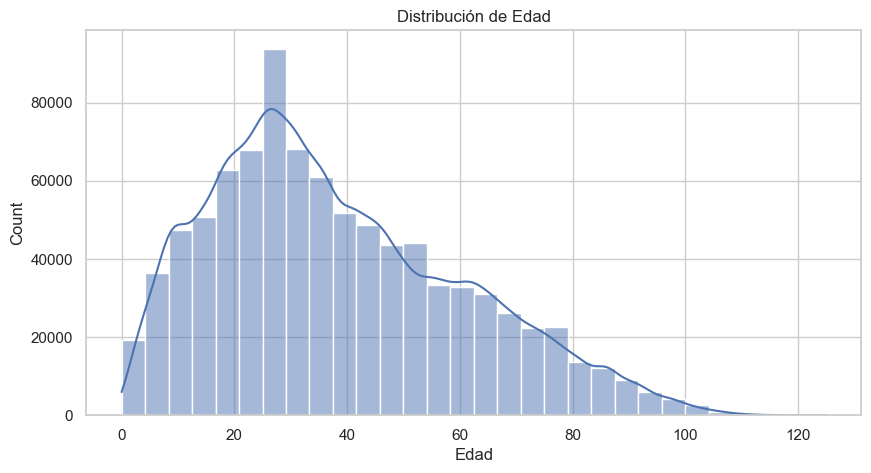

In [103]:
from datetime import datetime

current_year = datetime.now().year

person["age"] = (
    current_year -
    person["year_of_birth_clean"]
)

plt.figure(figsize=(10,5))

sns.histplot(
    person["age"],
    bins=30,
    kde=True
)

plt.title("Distribución de Edad")
plt.xlabel("Edad")
plt.show()

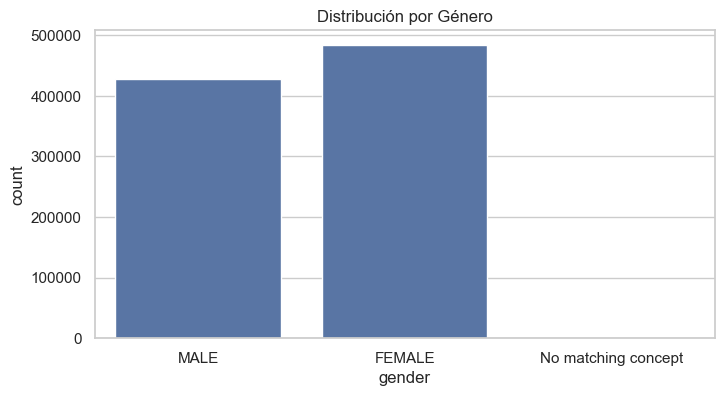

In [101]:
plt.figure(figsize=(8,4))

sns.countplot(
    data=person,
    x="gender"
)

plt.title("Distribución por Género")

plt.show()

In [102]:
person["gender"].value_counts(normalize=True)

gender
FEMALE                 0.530641
MALE                   0.469218
No matching concept    0.000141
Name: proportion, dtype: float64

Se observa una distribución relativamente balanceada entre pacientes femeninos (53.1%) y masculinos (46.9%).

Solo el 0.01% de los registros no pudieron asociarse a un concepto válido dentro de la tabla de vocabulario OMOP, lo que indica una alta integridad referencial para la variable gender_concept_id.

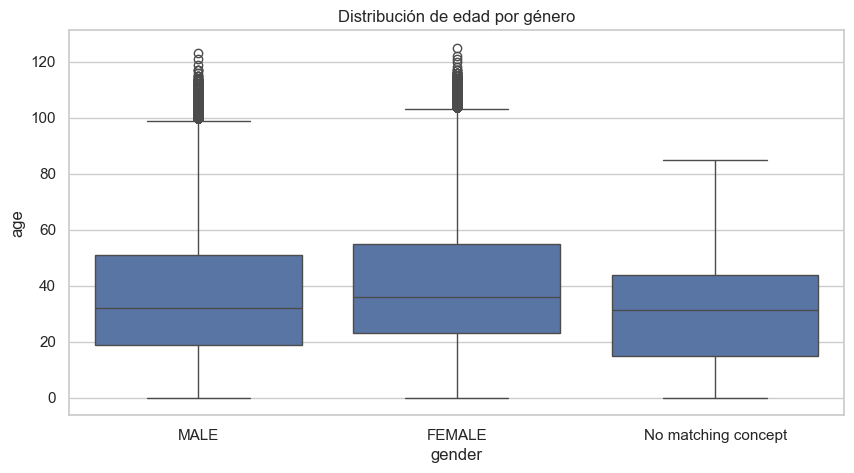

In [105]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=person,
    x="gender",
    y="age"
)

plt.title("Distribución de edad por género")

plt.show()

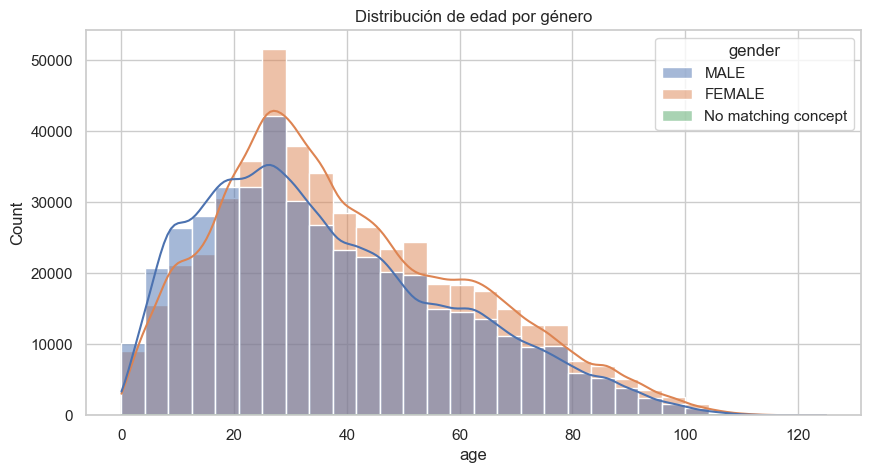

In [106]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=person,
    x="age",
    hue="gender",
    bins=30,
    kde=True
)

plt.title("Distribución de edad por género")

plt.show()

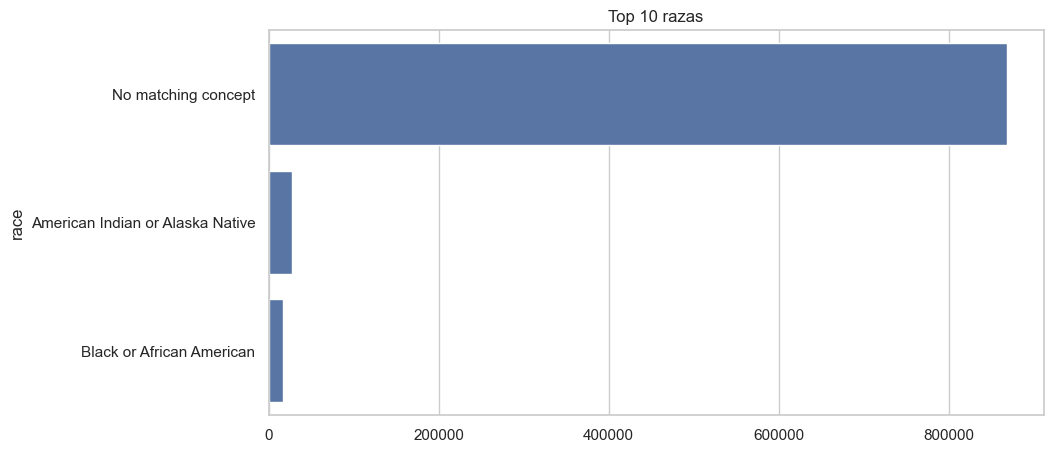

In [107]:
top_race = (
    person["race"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_race.values,
    y=top_race.index
)

plt.title("Top 10 razas")

plt.show()

In [109]:
person["race"].value_counts(normalize=True)

race
No matching concept                 0.951355
American Indian or Alaska Native    0.030370
Black or African American           0.018274
Name: proportion, dtype: float64

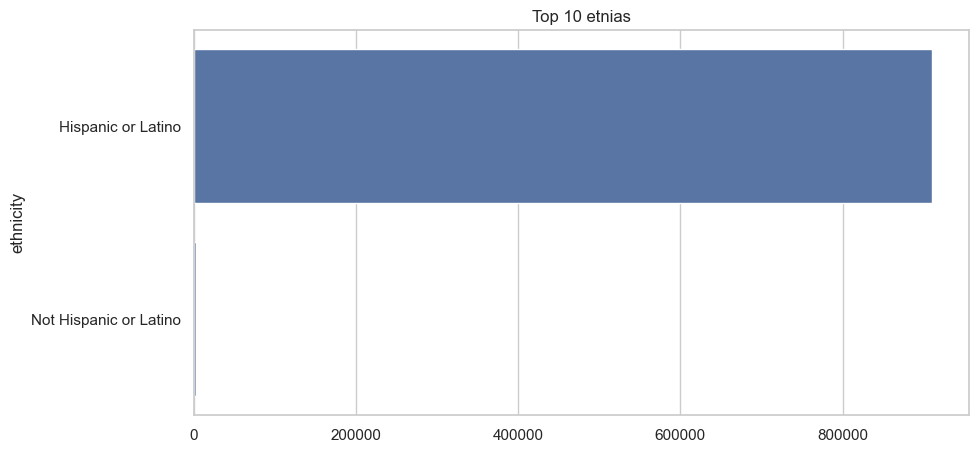

In [108]:
top_eth = (
    person["ethnicity"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=top_eth.values,
    y=top_eth.index
)

plt.title("Top 10 etnias")

plt.show()

In [111]:
person["ethnicity"].value_counts(normalize=True)

ethnicity
Hispanic or Latino        0.997736
Not Hispanic or Latino    0.002264
Name: proportion, dtype: float64

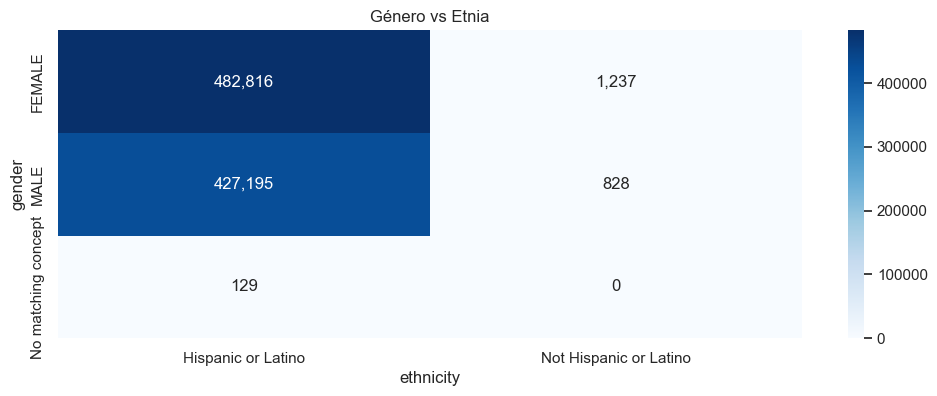

In [112]:
tabla = pd.crosstab(
    person["gender"],
    person["ethnicity"]
)

plt.figure(figsize=(12,4))

sns.heatmap(
    tabla,
    annot=True,
    fmt=",.0f",
    cmap="Blues"
)

plt.title(
    "Género vs Etnia"
)

plt.show()

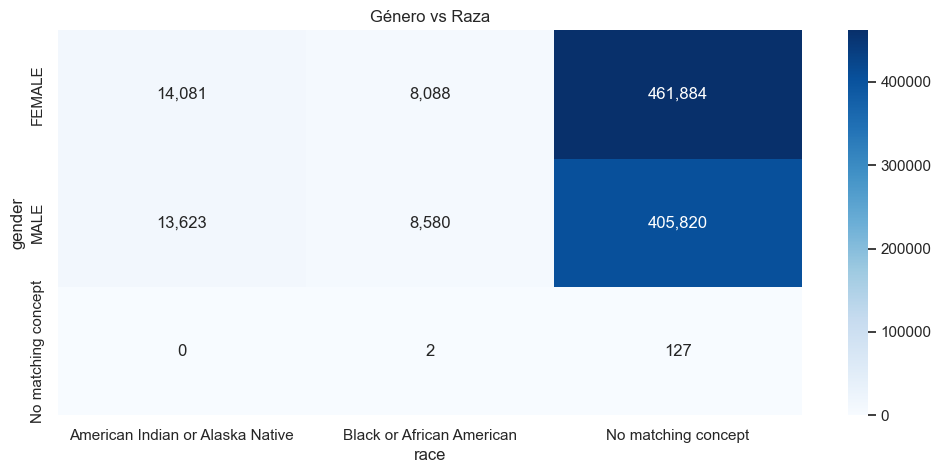

In [114]:
tabla = pd.crosstab(
    person["gender"],
    person["race"]
)

plt.figure(figsize=(12,5))

sns.heatmap(
    tabla,
    annot=True,
    fmt=",.0f",
    cmap="Blues"
)

plt.title(
    "Género vs Raza"
)

plt.show()

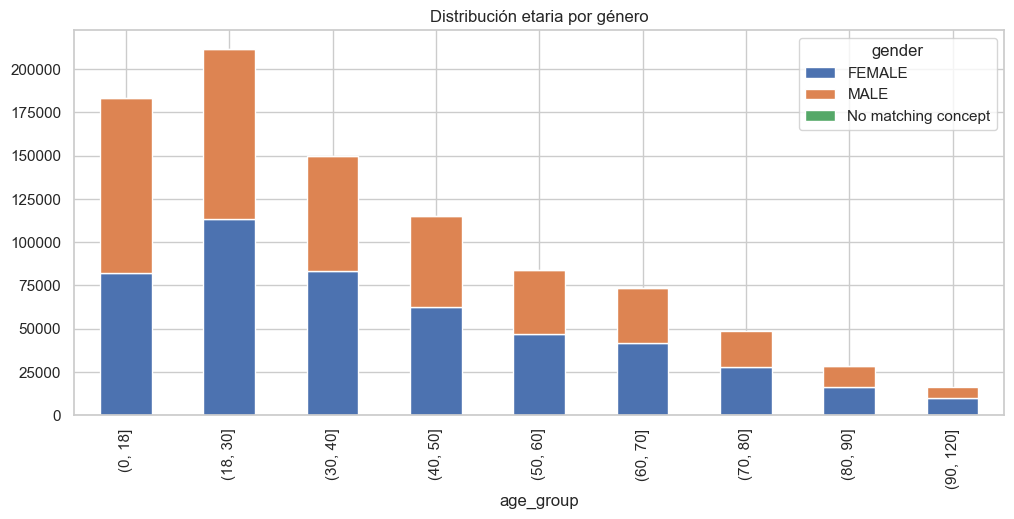

In [116]:
person["age_group"] = pd.cut(
    person["age"],
    bins=[0,18,30,40,50,60,70,80,90,120]
)

pivot = pd.crosstab(
    person["age_group"],
    person["gender"]
)

pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(12,5)
)

plt.title(
    "Distribución etaria por género"
)

plt.show()

In [134]:
# import pandas as pd
# import matplotlib.pyplot as plt

# # -----------------------------
# # Grupos etarios
# # -----------------------------

# person["age_group"] = pd.cut(
#     person["age"],
#     bins=[0,10,20,30,40,50,60,70,80,90,100,120],
#     right=False
# )

# # -----------------------------
# # Tabla para pirámide
# # -----------------------------

# pyramid = pd.crosstab(
#     person["age_group"],
#     person["gender"]
# )

# # Asegurar columnas
# for col in ["MALE", "FEMALE"]:
#     if col not in pyramid.columns:
#         pyramid[col] = 0

# # Totales
# pyramid["total"] = (
#     pyramid["MALE"] +
#     pyramid["FEMALE"]
# )

# total_persons = pyramid["total"].sum()

# pyramid["pct"] = (
#     pyramid["total"] /
#     total_persons * 100
# )

# # Hombres negativos
# male = -pyramid["MALE"]
# female = pyramid["FEMALE"]

# # -----------------------------
# # Colores más suaves
# # -----------------------------

# male_color = "#8C1414"
# female_color = "#3E952E"

# # -----------------------------
# # Gráfico
# # -----------------------------

# fig, ax = plt.subplots(
#     figsize=(12,8)
# )

# ax.barh(
#     pyramid.index.astype(str),
#     male,
#     color=male_color,
#     label="Male"
# )

# ax.barh(
#     pyramid.index.astype(str),
#     female,
#     color=female_color,
#     label="Female"
# )

# # Línea central

# ax.axvline(
#     0,
#     color="black",
#     linewidth=1
# )

# # -----------------------------
# # Etiquetas
# # -----------------------------

# for i, (
#     total,
#     pct
# ) in enumerate(
#     zip(
#         pyramid["total"],
#         pyramid["pct"]
#     )
# ):

#     ax.text(
#         0,
#         i,
#         f"{total:,}\n({pct:.1f}%)",
#         ha="center",
#         va="center",
#         fontsize=9,
#         fontweight="bold",
#         bbox=dict(
#             boxstyle="round,pad=0.3",
#             facecolor="white",
#             alpha=0.8
#         )
#     )

# # -----------------------------
# # Limpieza visual
# # -----------------------------

# ax.set_title(
#     "Pirámide poblacional de pacientes",
#     fontsize=16,
#     weight="bold"
# )

# ax.set_xlabel("")
# ax.set_ylabel("")

# ax.set_xticks([])

# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)
# ax.spines["bottom"].set_visible(True)

# ax.legend(
#     loc="lower right"
# )

# plt.tight_layout()

# # plt.show()

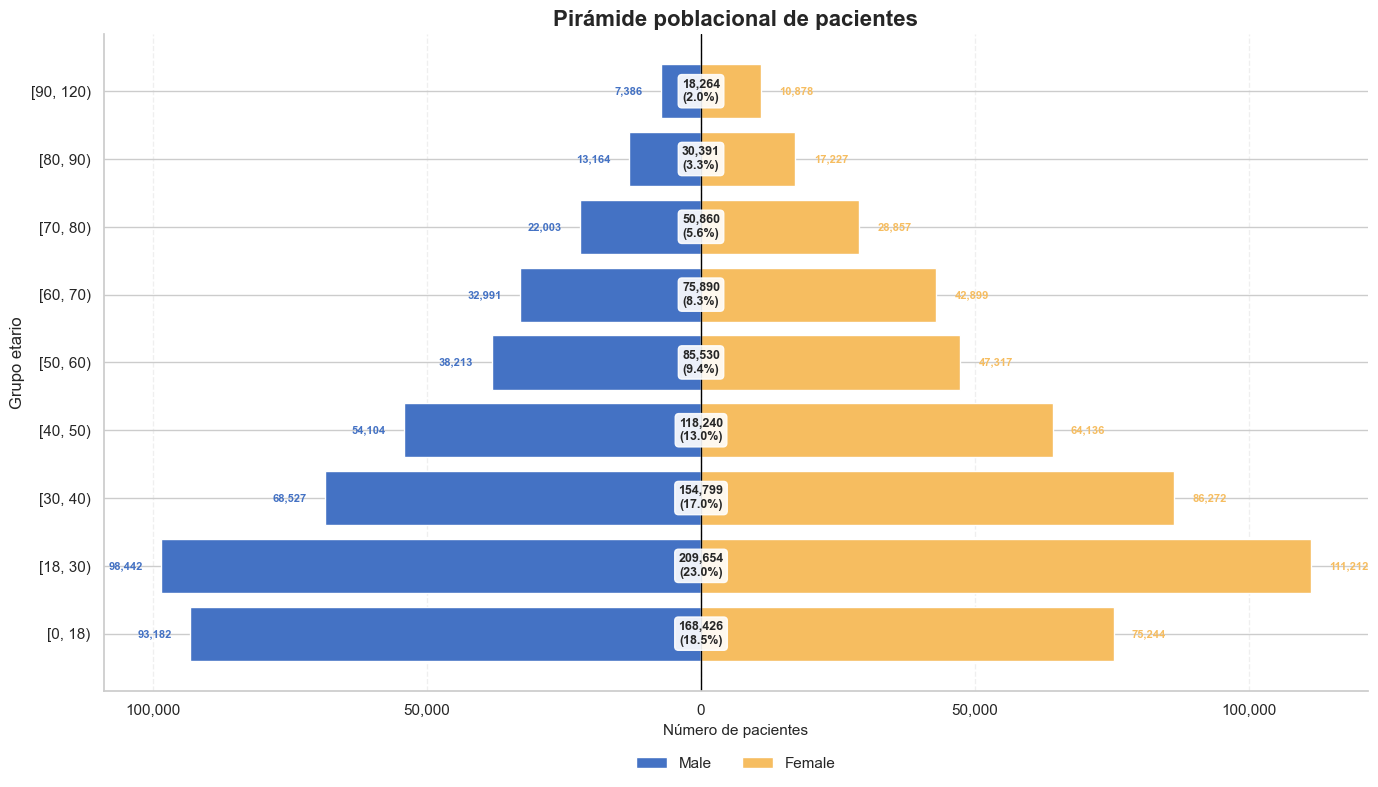

In [133]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# =====================================
# Crear grupos etarios
# =====================================

person["age_group"] = pd.cut(
    person["age"],
    bins=[0,18,30,40,50,60,70,80,90,120],
    right=False
)

# =====================================
# Tabla para la pirámide
# =====================================

pyramid = pd.crosstab(
    person["age_group"],
    person["gender"]
)

# Asegurar columnas
for col in ["MALE", "FEMALE"]:
    if col not in pyramid.columns:
        pyramid[col] = 0

# Totales
pyramid["total"] = (
    pyramid["MALE"] +
    pyramid["FEMALE"]
)

total_population = pyramid["total"].sum()

# % sobre la población total
pyramid["pct_population"] = (
    pyramid["total"] /
    total_population * 100
)

# % dentro del grupo etario
pyramid["male_pct"] = (
    pyramid["MALE"] /
    pyramid["total"] * 100
)

pyramid["female_pct"] = (
    pyramid["FEMALE"] /
    pyramid["total"] * 100
)

# =====================================
# Valores para la gráfica
# =====================================

male = -pyramid["MALE"]
female = pyramid["FEMALE"]

# =====================================
# Colores
# =====================================

male_color = "#4472C4"
female_color = "#F6BD60"

# =====================================
# Plot
# =====================================

fig, ax = plt.subplots(
    figsize=(14, 8)
)

ax.barh(
    pyramid.index.astype(str),
    male,
    color=male_color,
    label="Male"
)

ax.barh(
    pyramid.index.astype(str),
    female,
    color=female_color,
    label="Female"
)

# Línea central

ax.axvline(
    0,
    color="black",
    linewidth=1
)

# =====================================
# Etiquetas
# =====================================

max_width = max(
    pyramid["MALE"].max(),
    pyramid["FEMALE"].max()
)

for i, row in enumerate(
    pyramid.itertuples()
):

    # Centro
    ax.text(
        0,
        i,
        f"{row.total:,}\n({row.pct_population:.1f}%)",
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.9
        )
    )

    # Conteo masculino
    ax.text(
        -row.MALE - max_width*0.03,
        i,
        f"{row.MALE:,}",
        ha="right",
        va="center",
        fontsize=8,
        color=male_color,
        fontweight="bold"
    )

    # Conteo femenino
    ax.text(
        row.FEMALE + max_width*0.03,
        i,
        f"{row.FEMALE:,}",
        ha="left",
        va="center",
        fontsize=8,
        color=female_color,
        fontweight="bold"
    )

# =====================================
# Eje X
# =====================================

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, p: f"{abs(int(x)):,}"
    )
)

ax.set_xlabel(
    "Número de pacientes",
    fontsize=11
)

# Grid suave

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

# =====================================
# Estética
# =====================================

ax.set_title(
    "Pirámide poblacional de pacientes",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Grupo etario")

for spine in [
    "top",
    "right"
]:
    ax.spines[spine].set_visible(False)

# Leyenda inferior

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=2,
    frameon=False
)

plt.tight_layout()

plt.show()

In [117]:
for col in [
    "gender",
    "race",
    "ethnicity"
]:

    pct = (
        person[col]
        .isna()
        .mean()
        * 100
    )

    print(
        f"{col}: {pct:.4f}% sin mapeo"
    )

gender: 0.0000% sin mapeo
race: 0.0000% sin mapeo
ethnicity: 0.0000% sin mapeo


## 1.2 condition_occurrence.csv (sample = 1M)



### **1.2.1 Calidad de condition_ocurrence.csv**

Antes de empezar, debido al tamaño del archivo, se eligio una muestra aleatoria significativa para el analisis. El archivo condition_ocurrence.csv, se define de la siguiente manera:

- condition_occurrence_id: Identificador único de cada diagnóstico o condición clínica registrada.
- person_id: Identificador del paciente asociado al diagnóstico.
- visit_occurrence_id: Identificador de la visita relacionada con el diagnóstico registrado.
- condition_concept_id: Identificador estandarizado del diagnóstico o condición clínica.
- condition_start_datetime: Fecha y hora de inicio o registro de la condición clínica.

In [171]:
condition_ocurrence = cargar_parquet(
    "condition_occurrence_sample_1M.parquet"
)

In [15]:
analizar_tabla(condition_ocurrence, "condition_occurrence")

TABLA: condition_occurrence

Filas: 1,000,000
Columnas: 6
Memoria: 45.78 MB

Duplicados: 0

Top faltantes:


,nulos,pct_nulos
visit_occurrence_id,20355,2.04
condition_occurrence_id,0,0.00
person_id,0,0.00
condition_concept_id,0,0.00
condition_start_datetime,0,0.00
condition_type_concept_id,0,0.00



Resumen estadístico:


,count,mean,min,25%,50%,75%,max,std
condition_occurrence_id,1000000.0,52710000.257503,1281.0,36377134.5,56561579.0,66333921.25,105426204.0,25488397.666059
person_id,1000000.0,709392.480362,2646.0,642279.0,790058.0,847086.0,912171.0,207605.495247
visit_occurrence_id,979645.0,2520740.58621,657231.0,2480458.0,2746733.0,3002589.0,3262287.0,710716.518251
condition_concept_id,1000000.0,2185759.955164,0.0,0.0,197344.0,440029.0,46287148.0,7461733.655669
condition_start_datetime,1000000,2024-09-21 19:54:12.093335296,2023-01-01 00:11:13,2023-10-29 01:22:53,2024-09-26 22:57:25.500000,2025-08-08 16:29:19,2033-05-29 09:38:26,NaN
condition_type_concept_id,1000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


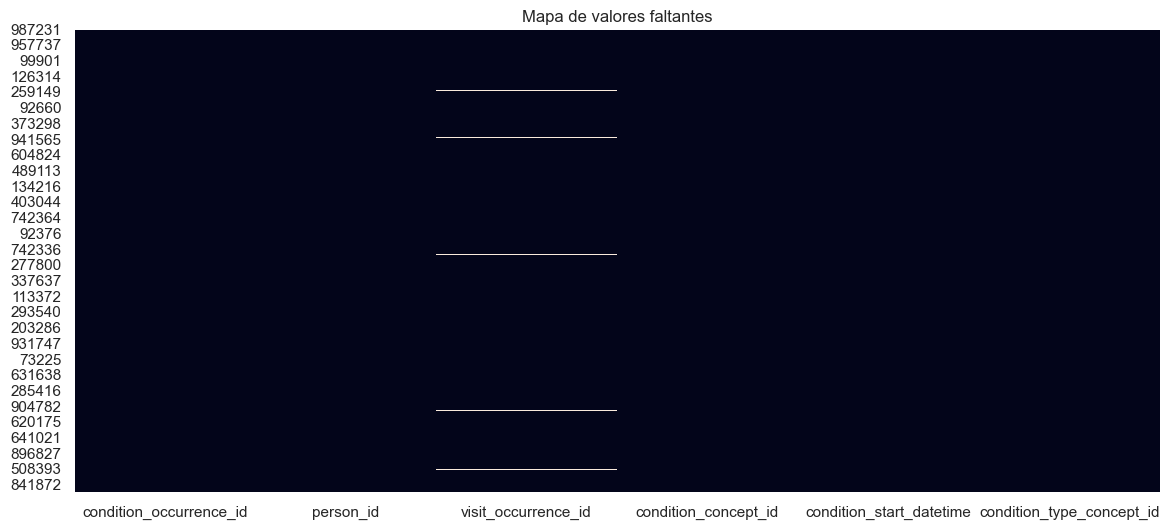

In [17]:
heatmap_nulos(condition_ocurrence)

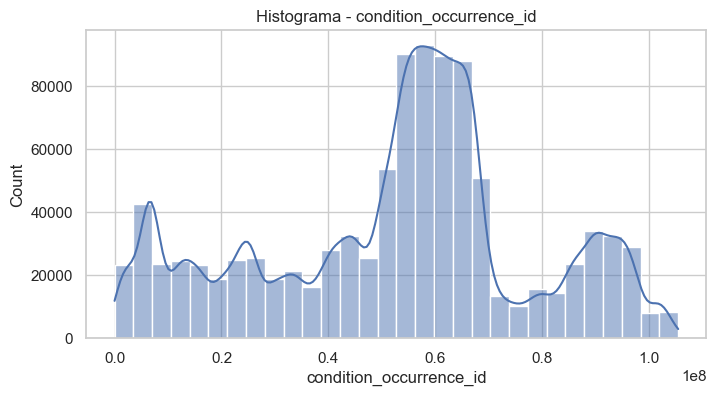

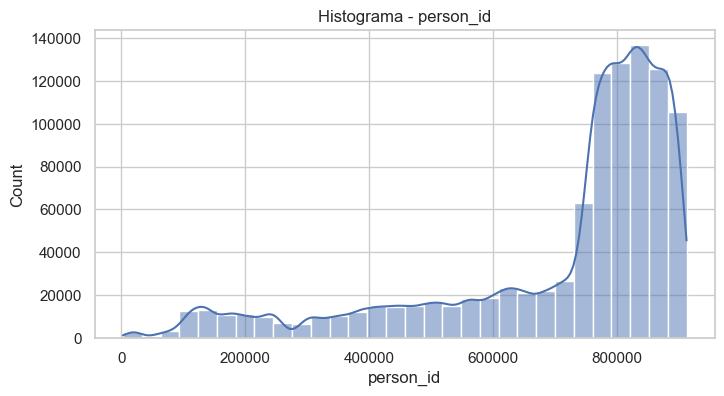

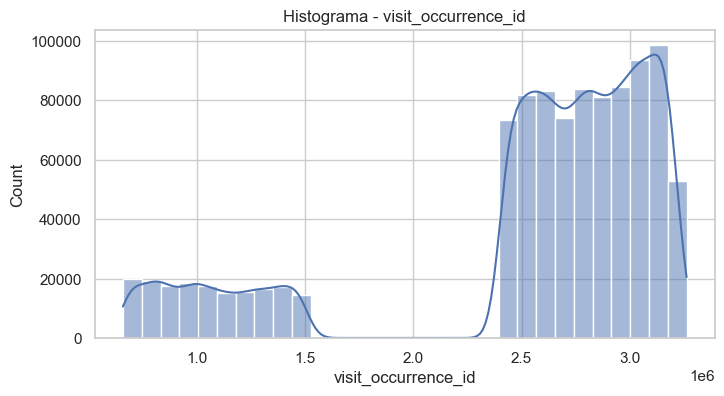

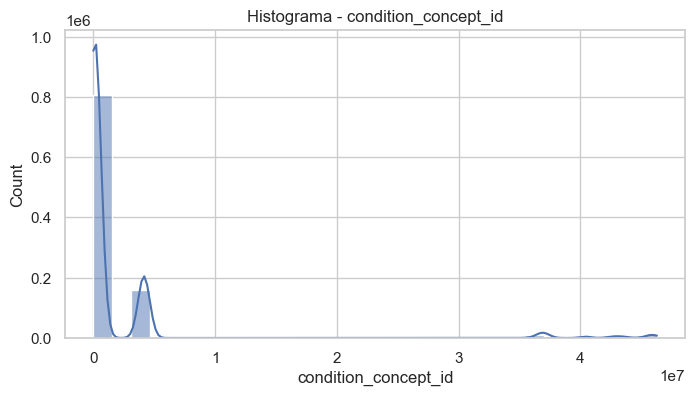

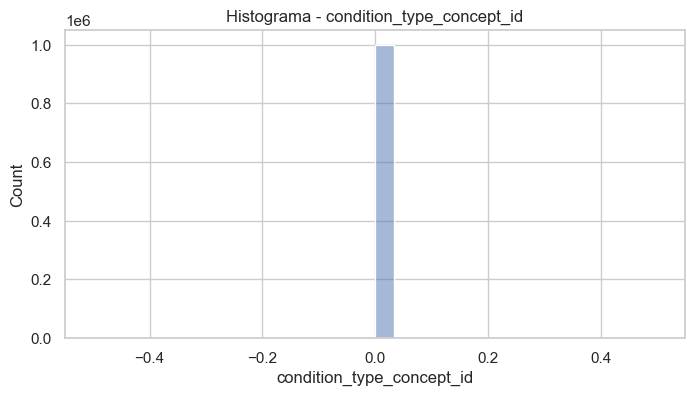

In [18]:
histogramas(condition_ocurrence)

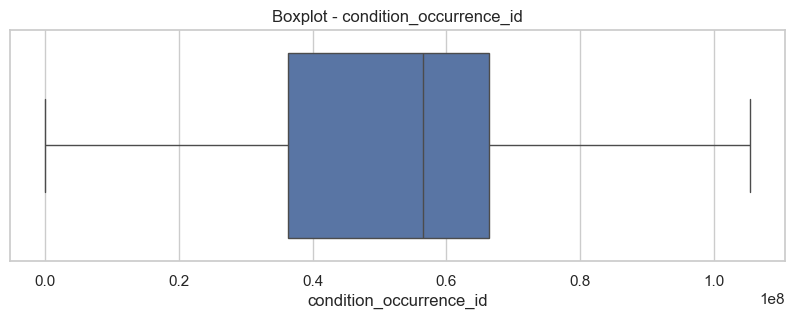

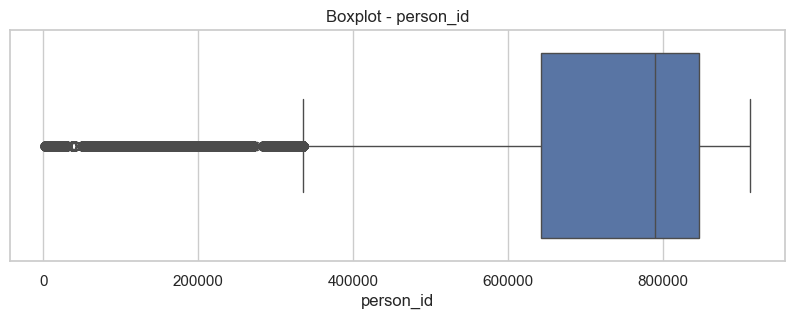

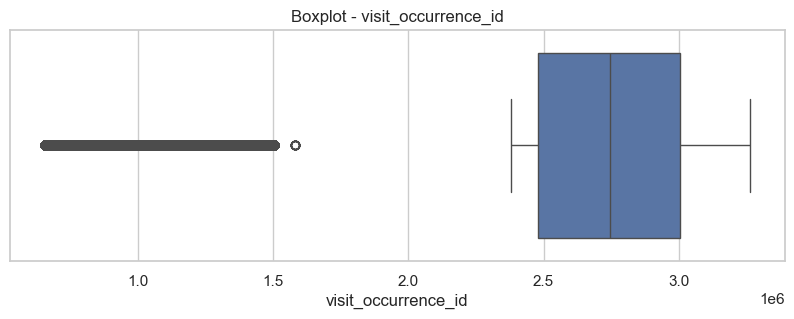

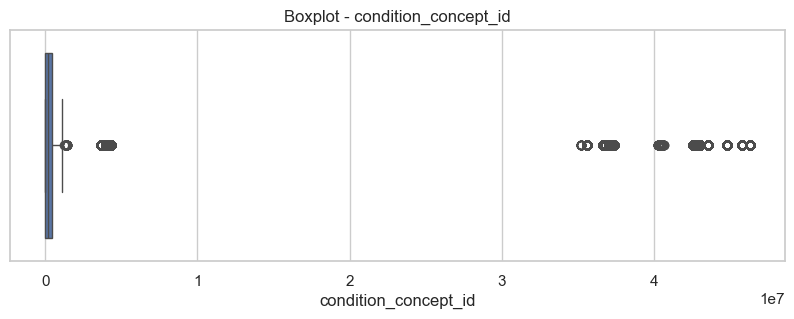

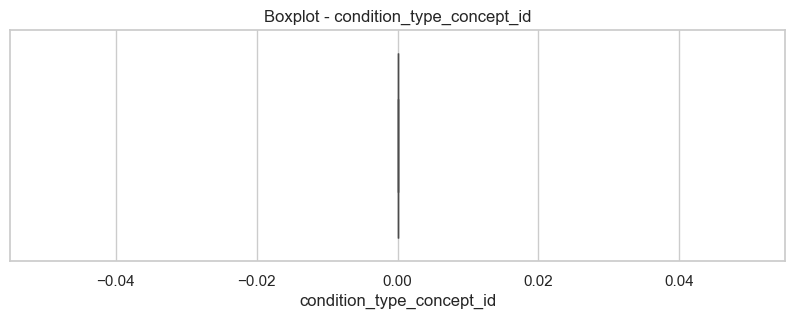

In [19]:
boxplots(condition_ocurrence)

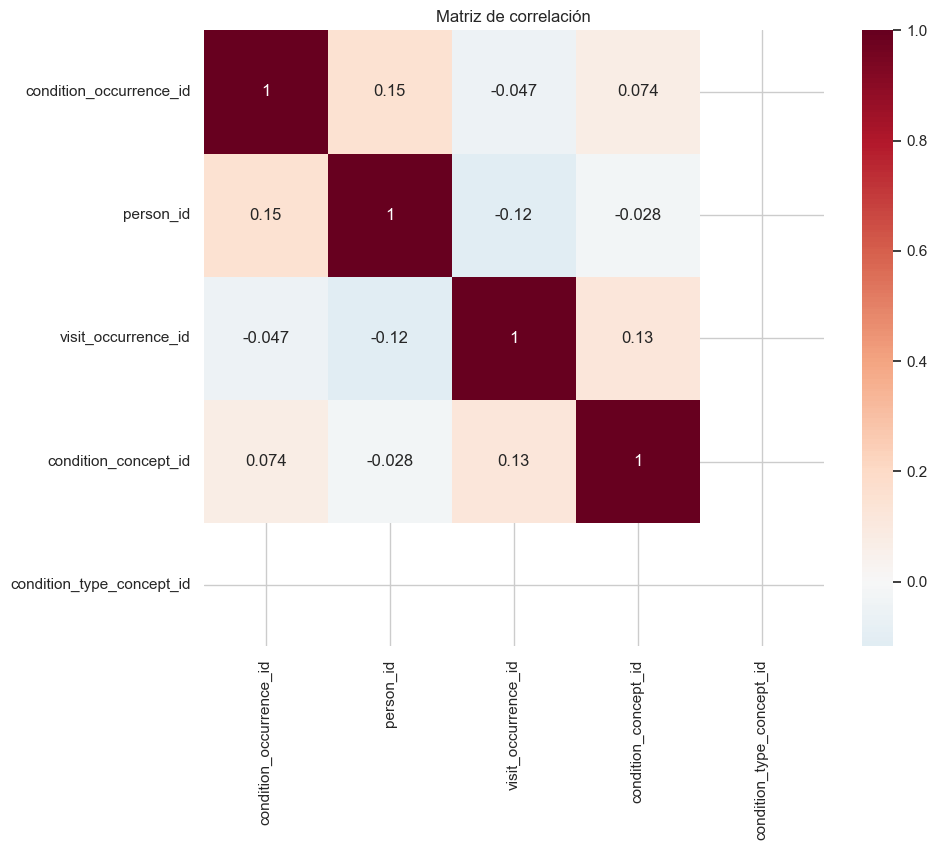

In [29]:
correlaciones(condition_ocurrence)

### **1.2.2 Tratamiento de la variable condition_type_concept_id y visit_concurrence_id**

In [149]:
condition_ocurrence["condition_type_concept_id"] \
    .value_counts(dropna=False)


condition_occurrence_clean = (
    condition_ocurrence
    .drop(columns=["condition_type_concept_id"])
)

La variable presenta un único valor para todos los registros analizados (0).

Al no aportar variabilidad ni capacidad discriminativa, se excluye de los análisis posteriores.

In [150]:
condition_ocurrence["visit_occurrence_id"].notna().mean() * 100

np.float64(97.9645)

La variable visit_occurrence_id presentó 20.355 registros nulos (2.04%).

Esto implica que el 97.96% de los diagnósticos mantienen una relación válida con una visita hospitalaria dentro del modelo OMOP.

Aunque existe una pequeña pérdida de integridad referencial, el nivel de completitud observado es alto y permite continuar con el análisis.

### **1.2.3 Exploracion y analisis de los datos de condition_ocurrence.csv**

In [151]:
[col for col in condition_ocurrence.columns if "concept_id" in col]

['condition_concept_id', 'condition_type_concept_id']

In [152]:
condition_ocurrence["condition"] = (
    condition_ocurrence["condition_concept_id"]
    .map(concept_dict)
)

condition_ocurrence["condition_type"] = (
    condition_ocurrence["condition_type_concept_id"]
    .map(concept_dict)
)

In [153]:
condition_ocurrence[
    [
        "condition_concept_id",
        "condition"
    ]
].head()

,condition_concept_id,condition
0,0,No matching concept
1,4296653,Acute ST segment elevation myocardial infarction
2,4064296,Prem rupture of membranes onset of labor withi...
3,0,No matching concept
4,4169915,Vomiting in newborn


In [154]:
(
    condition_ocurrence["condition"]
    .value_counts()
    .head(20)
)

condition
No matching concept                                       379633
Localized infection of skin AND/OR subcutaneous tissue     30346
Urinary tract infectious disease                           28862
Renal colic                                                16818
Cerebrovascular accident                                   11452
Congestive heart failure                                   11071
Disorder of intestine                                       9916
Gastrointestinal hemorrhage                                 8705
Abdominal pain                                              8662
Bacterial pneumonia                                         7554
Cellulitis                                                  7165
Heart failure                                               6530
Acute cholecystitis                                         6523
Headache                                                    6380
Delivery by emergency cesarean section                      6172
Pneumonia      

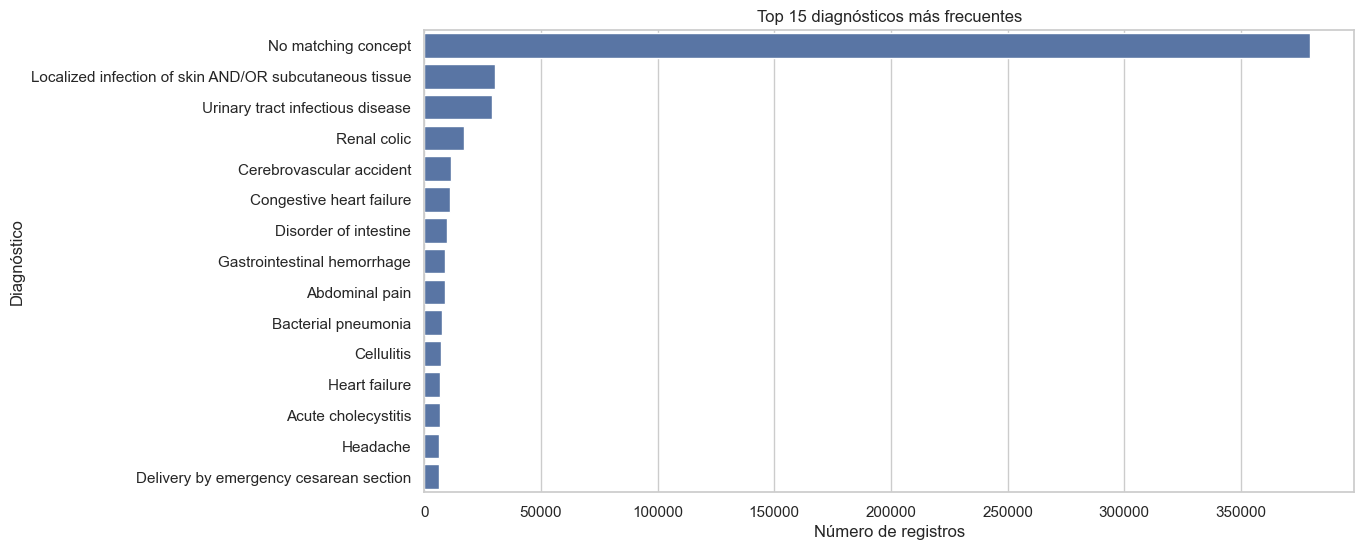

In [155]:
top_conditions = (
    condition_ocurrence["condition"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_conditions.values,
    y=top_conditions.index
)

plt.title(
    "Top 15 diagnósticos más frecuentes"
)

plt.xlabel("Número de registros")
plt.ylabel("Diagnóstico")

plt.show()

In [156]:
missing_ids = (
    condition_ocurrence.loc[
        condition_ocurrence["condition"] == "No matching concept",
        "condition_concept_id"
    ]
    .value_counts()
)

missing_ids.head(20)

condition_concept_id
0    379633
Name: count, dtype: int64

In [161]:
diagnosticos_validos = (
    condition_ocurrence[
        condition_ocurrence["condition"]
        != "No matching concept"
    ]
)

top_dx = (
    diagnosticos_validos["condition"]
    .value_counts()
    .head(15)
)

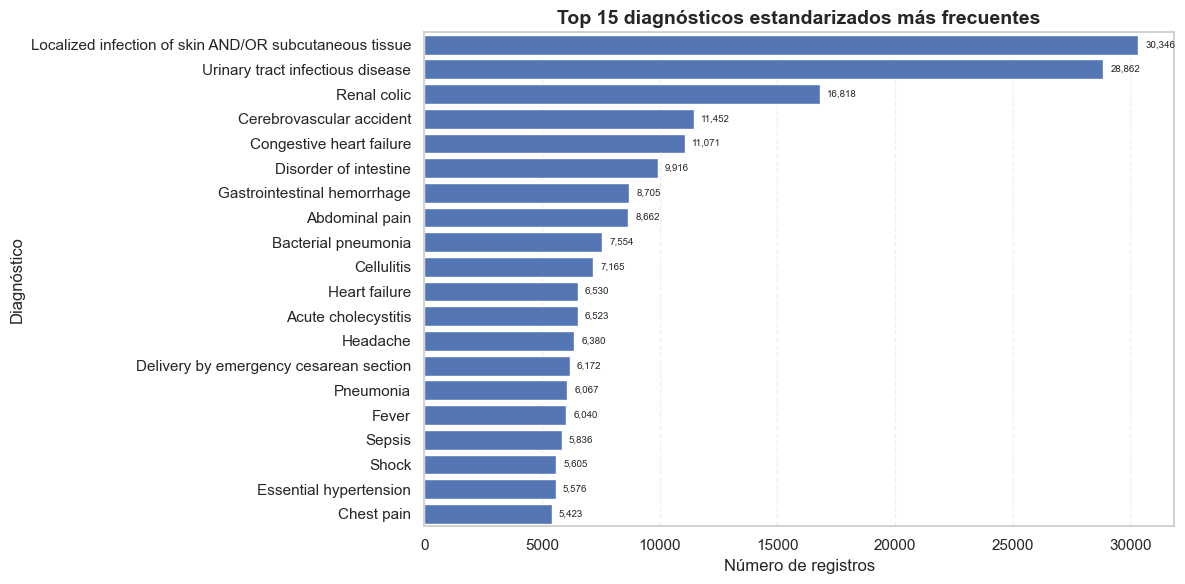

In [169]:
top_dx = (
    condition_ocurrence
    .query("condition != 'No matching concept'")
    ["condition"]
    .value_counts()
    .head(20)
)

fig, ax = plt.subplots(figsize=(12,6))

sns.barplot(
    x=top_dx.values,
    y=top_dx.index,
    color="#4472C4",
    ax=ax
)

for i, v in enumerate(top_dx.values):
    ax.text(
        v + top_dx.max()*0.01,
        i,
        f"{v:,}",
        va="center",
        fontsize=7
    )

ax.set_title(
    "Top 15 diagnósticos estandarizados más frecuentes",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Número de registros")
ax.set_ylabel("Diagnóstico")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [175]:
condition_ocurrence['mes'] = condition_ocurrence['condition_start_datetime'].dt.to_period('M')
condition_ocurrence['dia_semana'] = condition_ocurrence['condition_start_datetime'].dt.day_name()
condition_ocurrence['hora'] = condition_ocurrence['condition_start_datetime'].dt.hour


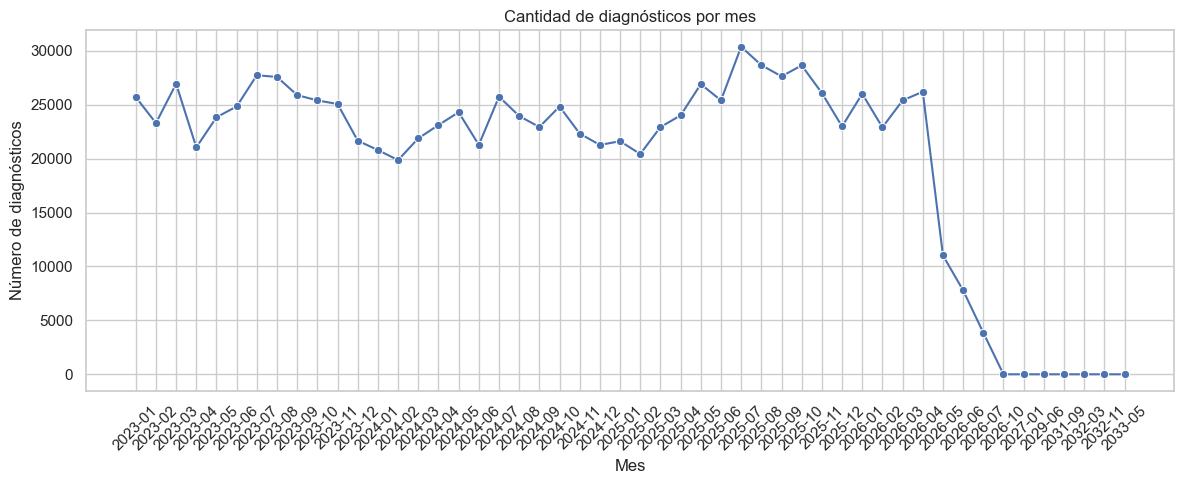

In [177]:
meses = (
    condition_ocurrence
    .groupby(condition_ocurrence["condition_start_datetime"].dt.to_period("M"))
    .size()
    .reset_index(name="cantidad")
)

meses["condition_start_datetime"] = meses[
    "condition_start_datetime"
].astype(str)

plt.figure(figsize=(12,5))
sns.lineplot(
    data=meses,
    x="condition_start_datetime",
    y="cantidad",
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Cantidad de diagnósticos por mes")
plt.xlabel("Mes")
plt.ylabel("Número de diagnósticos")
plt.tight_layout()
plt.show()

C:\Users\taran\AppData\Local\Temp\ipykernel_18872\631278405.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


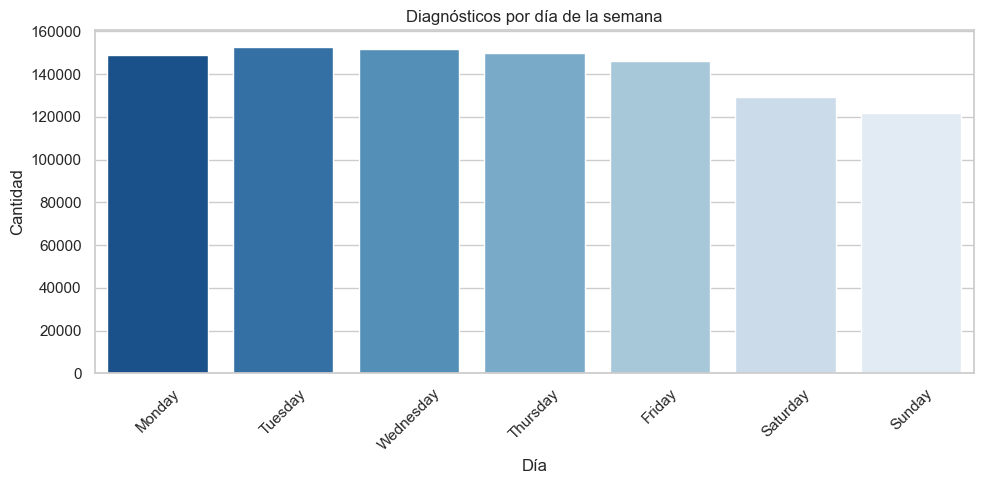

In [178]:
orden = [
    "Monday","Tuesday","Wednesday",
    "Thursday","Friday","Saturday","Sunday"
]

dias = (
    condition_ocurrence["condition_start_datetime"]
    .dt.day_name()
    .value_counts()
    .reindex(orden)
)

plt.figure(figsize=(10,5))
sns.barplot(
    x=dias.index,
    y=dias.values,
    palette="Blues_r"
)

plt.title("Diagnósticos por día de la semana")
plt.xlabel("Día")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


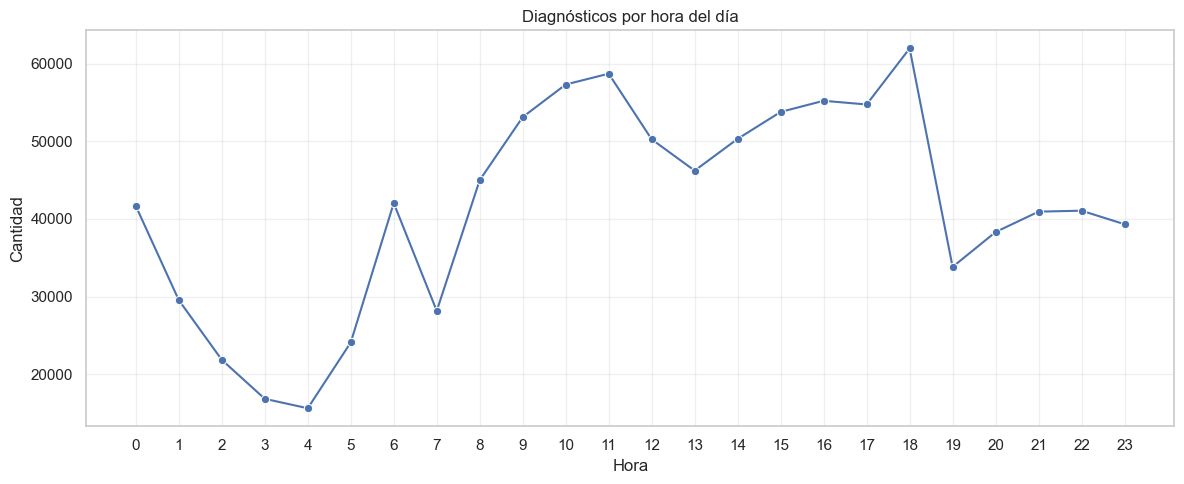

In [181]:
hora = (
    condition_ocurrence["condition_start_datetime"]
    .dt.hour
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,5))
sns.lineplot(
    x=hora.index,
    y=hora.values,
    marker="o"
)

plt.title("Diagnósticos por hora del día")
plt.xlabel("Hora")
plt.ylabel("Cantidad")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 1.3 procedure_ocurrence.csv (sample = 1M)


### **1.3.1 Calidad de procedure_ocurrence.csv**

- procedure_occurrence_id: Identificador único de cada procedimiento realizado.
- person_id: Identificador del paciente asociado al procedimiento.
- visit_occurrence_id: Identificador de la visita asociada al procedimiento realizado.
- procedure_concept_id: Identificador estandarizado del procedimiento clínico realizado.
- procedure_datetime: Fecha y hora de realización del procedimiento.
- procedure_type_concept_id: Identificador asociado al tipo u origen del procedimiento registrado.

In [183]:
procedure_ocurrence = cargar_parquet(
    "procedure_occurrence_sample_1M.parquet"
)

In [23]:
analizar_tabla(procedure_ocurrence, "procedure_occurrence")

TABLA: procedure_occurrence

Filas: 1,000,000
Columnas: 5
Memoria: 53.41 MB

Duplicados: 0

Top faltantes:


,nulos,pct_nulos
procedure_date,1000000,100.00
visit_occurrence_id,8352,0.84
procedure_occurrence_id,0,0.00
person_id,0,0.00
procedure_concept_id,0,0.00



Resumen estadístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
procedure_occurrence_id,1000000.0,NaN,NaN,NaN,75874424.550635,35689940.384519,443732.0,47984167.5,91417635.0,105064882.0,117010258.0
person_id,1000000.0,NaN,NaN,NaN,650132.94172,230993.928404,2668.0,499176.0,749953.0,834230.0,911652.0
visit_occurrence_id,991648.0,NaN,NaN,NaN,2040025.331297,910804.907213,542223.0,1151825.0,2463352.0,2910343.0,3262244.0
procedure_concept_id,1000000.0,NaN,NaN,NaN,5847670.98229,8905900.883063,706553.0,3024641.0,4138350.0,4194672.0,46287143.0
procedure_date,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


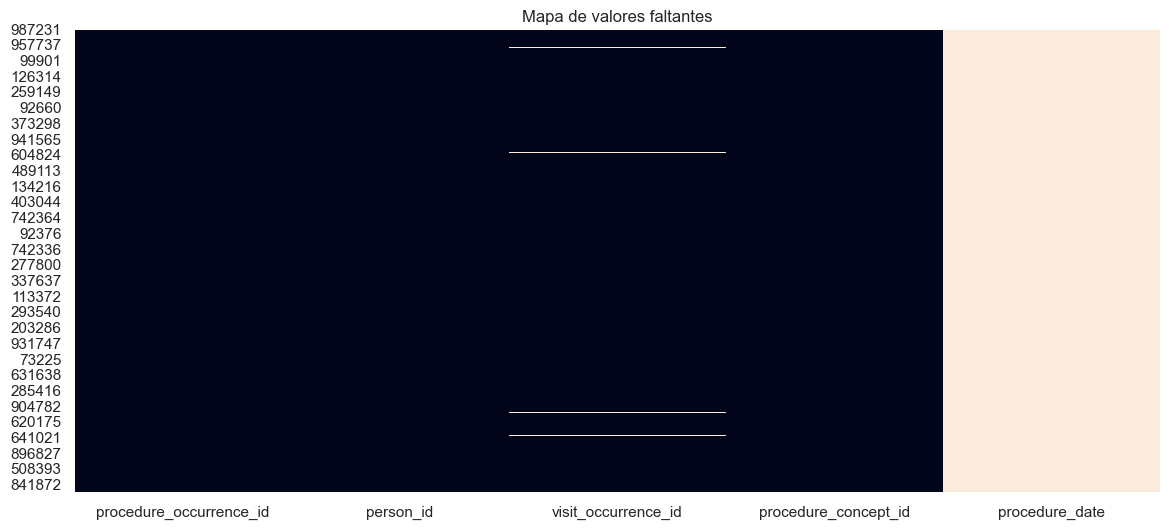

In [24]:
heatmap_nulos(procedure_ocurrence)

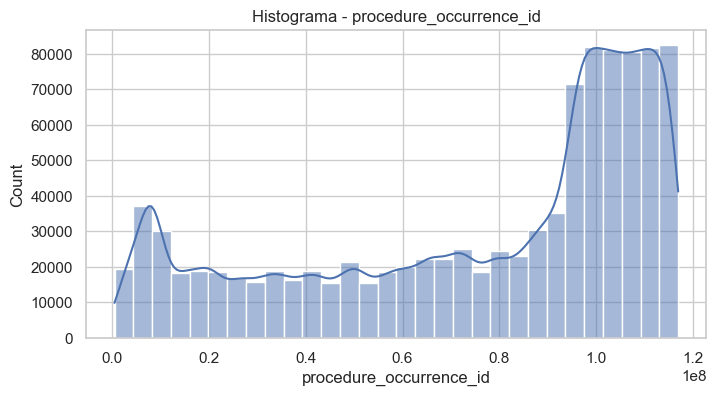

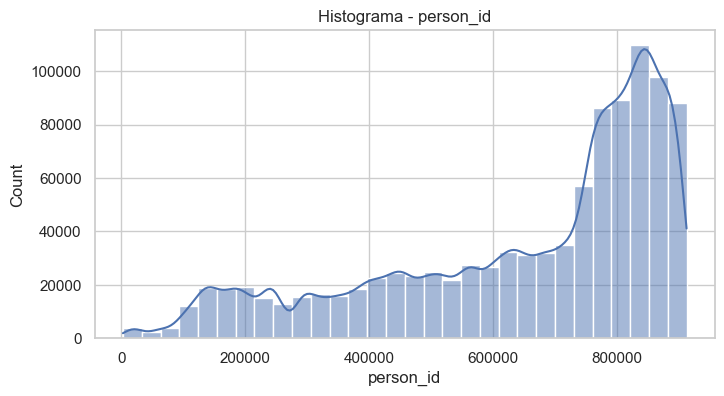

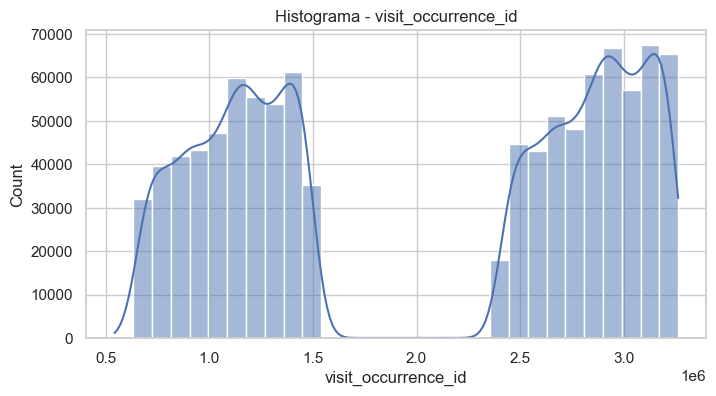

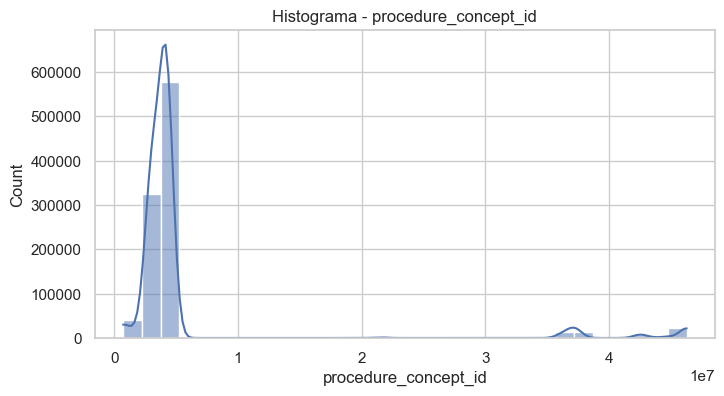

In [25]:
histogramas(procedure_ocurrence)

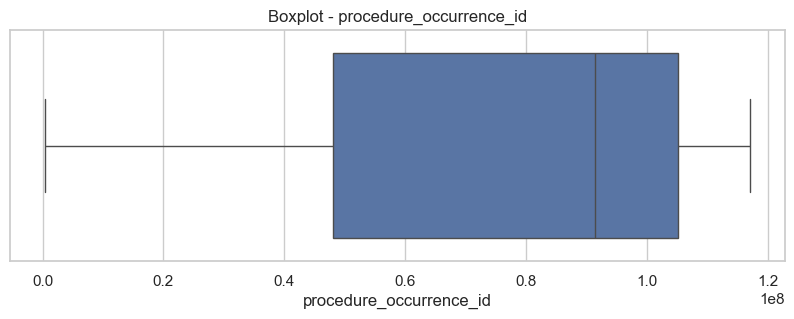

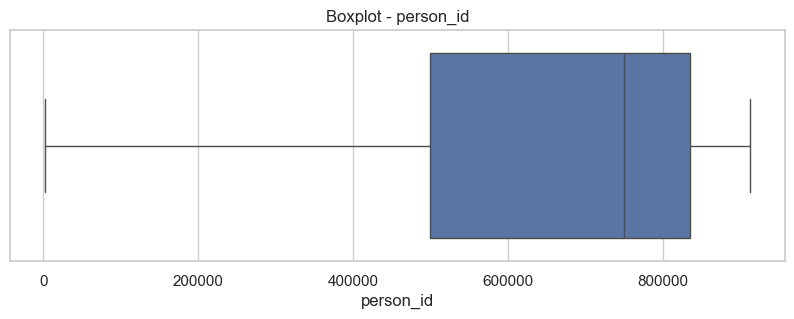

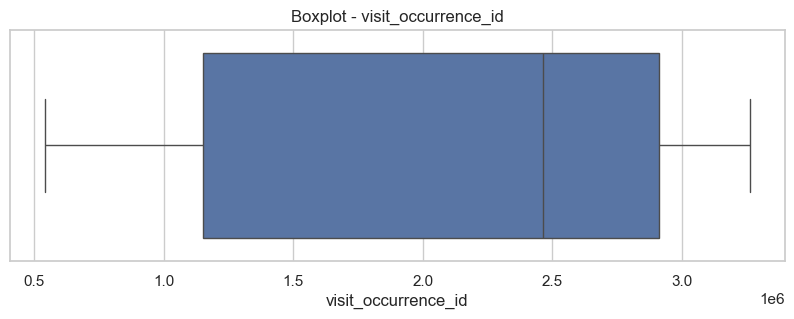

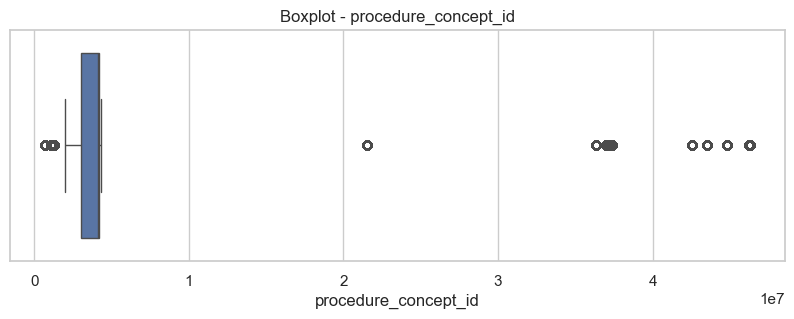

In [26]:
boxplots(procedure_ocurrence)

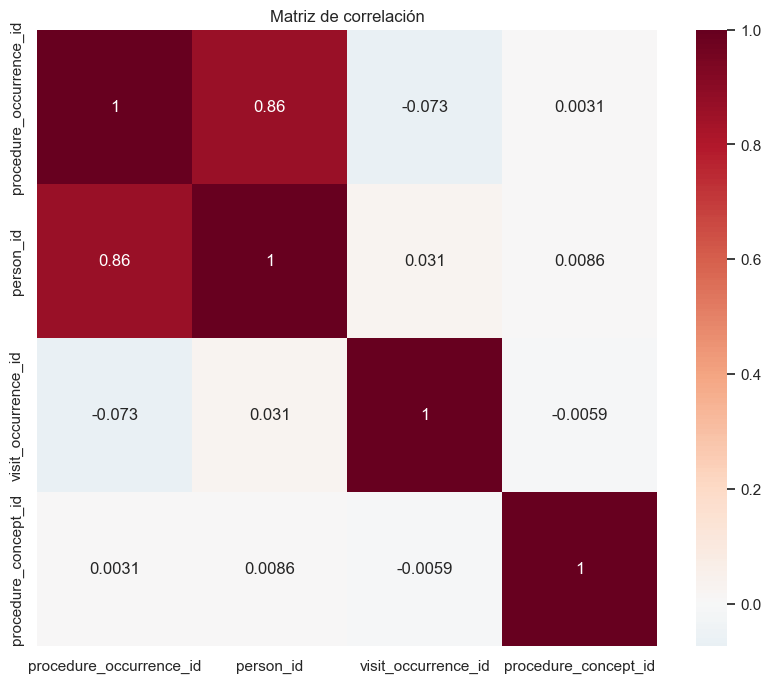

In [27]:
correlaciones(procedure_ocurrence)

### **1.3.2 Tratamiento de la variable procedure_date y visit_occurrence_id**

In [ ]:
procedure_ocurrence["procedure_date"].isna().mean() * 100

np.float64(100.0)

La variable procedure_date presenta un 100% de valores nulos, por lo que no fue considerada en el análisis temporal de procedimientos.

In [189]:
procedure_ocurrence = procedure_ocurrence.drop(columns=["procedure_date"])

In [191]:
procedure_ocurrence["visit_occurrence_id"].isna().mean() * 100

np.float64(0.8352)

In [190]:
procedure_ocurrence[procedure_ocurrence["visit_occurrence_id"].isna()].head()

,procedure_occurrence_id,person_id,visit_occurrence_id,procedure_concept_id
126,27605441,288516,NaN,3033745
255,3151358,288516,NaN,4184637
304,114712432,891757,NaN,4203780
433,2914758,288516,NaN,4080075
554,34596361,350101,NaN,4144235


visit_occurrence_id:
- 0.084% de valores nulos.
- Se conserva la variable debido a su alta completitud.
- Los registros sin identificador de visita se excluyen únicamente en análisis que requieren vinculación con la tabla visit_occurrence.

### **1.3.3 Exploracion y analisis de datos de procedure_ocurrence.csv**

In [ ]:
concept = cargar_csv(
    "concept.csv"
)

concept_dict = dict(
    zip(
        concept["concept_id"],
        concept["concept_name"]
    )
)

In [192]:
[col for col in procedure_ocurrence.columns if "concept_id" in col]

['procedure_concept_id']

In [193]:
procedure_ocurrence["procedure"] = (
    procedure_ocurrence["procedure_concept_id"]
    .map(concept_dict)
)

In [194]:
(
    procedure_ocurrence["procedure"]
    .value_counts()
    .head(20)
)

procedure
Glucose measurement, blood                                                                                        101351
Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Platelet count, and automated complete WBC differential     63553
Emergency department Medical records                                                                               62973
Specialized medical examination                                                                                    60346
Emergency department Consult note                                                                                  53191
Creatinine measurement                                                                                             50334
Urea nitrogen [Moles/volume] in Serum or Plasma                                                                    49963
Serum potassium measurement                                                                                        41176
Sodium [Moles/volume] 

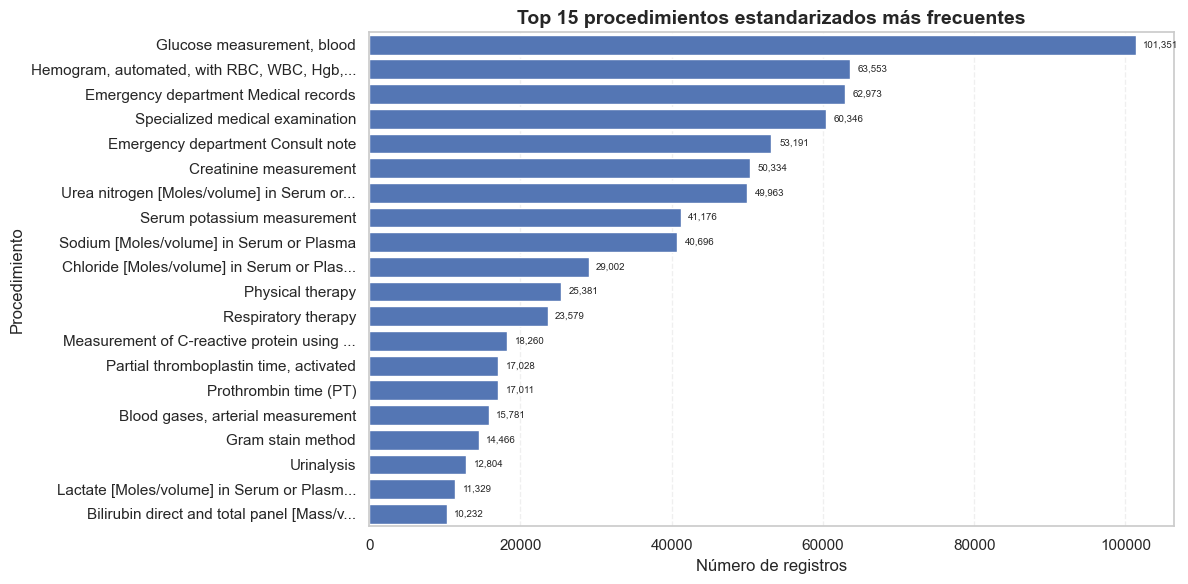

In [198]:
top_dx = (
    procedure_ocurrence
    .query("procedure != 'No matching concept'")
    ["procedure"]
    .value_counts()
    .head(20)
)

top_dx.index = [
    texto[:40] + "..."
    if len(texto) > 40
    else texto
    for texto in top_dx.index
]

fig, ax = plt.subplots(figsize=(12,6))

sns.barplot(
    x=top_dx.values,
    y=top_dx.index,
    color="#4472C4",
    ax=ax
)

for i, v in enumerate(top_dx.values):
    ax.text(
        v + top_dx.max()*0.01,
        i,
        f"{v:,}",
        va="center",
        fontsize=7
    )

ax.set_title(
    "Top 15 procedimientos estandarizados más frecuentes",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Número de registros")
ax.set_ylabel("Procedimiento")

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [201]:
(
    procedure_ocurrence
    .groupby("visit_occurrence_id")
    .size()
)

visit_occurrence_id
542223.0       7
570967.0       1
641522.0      59
643700.0      13
646481.0     138
            ... 
3261630.0      1
3261663.0      2
3261726.0      1
3262048.0      1
3262244.0      1
Length: 77348, dtype: int64

## 1.4 measurement (sample = 1M)
 


- measurement_id: Identificador único de cada medición clínica registrada.
- person_id: Identificador del paciente asociado a la medición clínica.
- visit_occurrence_id: Identificador de la visita asociada a la medición realizada.
- measurement_concept_id: Identificador estandarizado de la medición clínica o laboratorio realizado.
- measurement_datetime: Fecha y hora de realización de la medición clínica.
- value_as_number: Valor numérico asociado al resultado de la medición clínica.
- unit_concept_id: Identificador estandarizado de la unidad de medida utilizada.
- measurement_type_concept_id: Identificador asociado al tipo u origen de la medición registrada.

In [33]:
measurement = cargar_parquet(
    "measurement_sample_1M.parquet"
)

In [34]:
analizar_tabla(measurement, "measurement")

TABLA: measurement

Filas: 1,000,000
Columnas: 7
Memoria: 857.06 MB

Duplicados: 0

Top faltantes:


,nulos,pct_nulos
value_as_number,383843,38.38
visit_occurrence_id,18371,1.84
measurement_id,0,0.00
person_id,0,0.00
measurement_concept_id,0,0.00
measurement_datetime,0,0.00
measurement_source_value_extended,0,0.00



Resumen estadístico:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
measurement_id,1000000.0,NaN,NaN,NaN,17616678.785241,397.0,9938208.75,20746828.5,24940271.25,29093904.0,8820828.892528
person_id,1000000.0,NaN,NaN,NaN,647935.230692,1269.0,494811.0,760597.0,833210.0,912185.0,236128.720121
visit_occurrence_id,981629.0,NaN,NaN,NaN,2828212.326285,2337538.0,2626181.0,2832625.0,3035889.0,3262308.0,239646.734151
measurement_concept_id,1000000.0,NaN,NaN,NaN,2238280.477097,0.0,0.0,0.0,4016928.0,46287143.0,4557002.31292
measurement_datetime,1000000,NaN,NaN,NaN,2024-09-24 03:49:59.918163456,2023-01-01 02:28:35,2023-11-18 07:08:44,2024-09-29 09:33:24,2025-07-30 06:04:47,2026-07-17 18:58:28,NaN
value_as_number,616157.0,NaN,NaN,NaN,25.463121,0.0,0.14,4.56,22.8,1411.0,57.714447
measurement_source_value_extended,1000000,198506,COLORACION GRAM : MUESTRA: :ORINA ...,1995,NaN,NaN,NaN,NaN,NaN,NaN,NaN


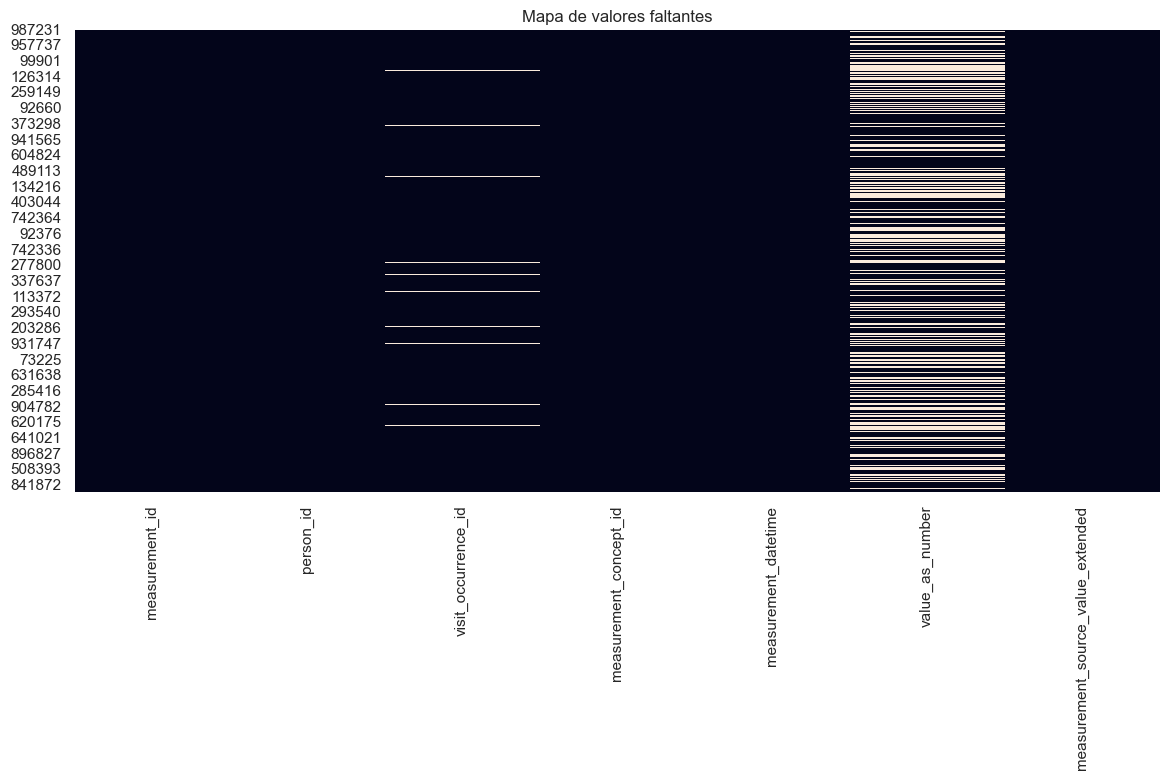

In [35]:
heatmap_nulos(measurement)

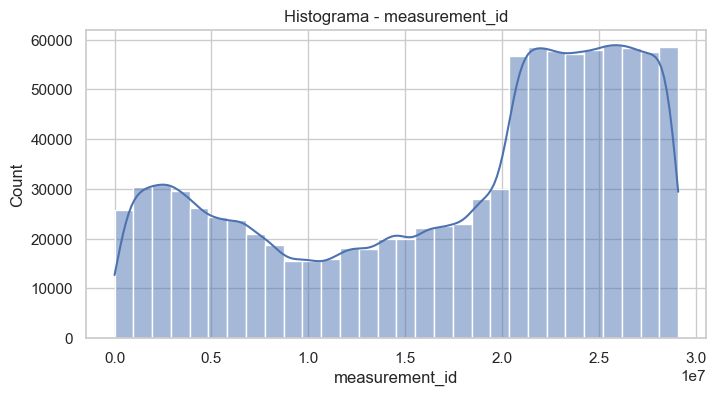

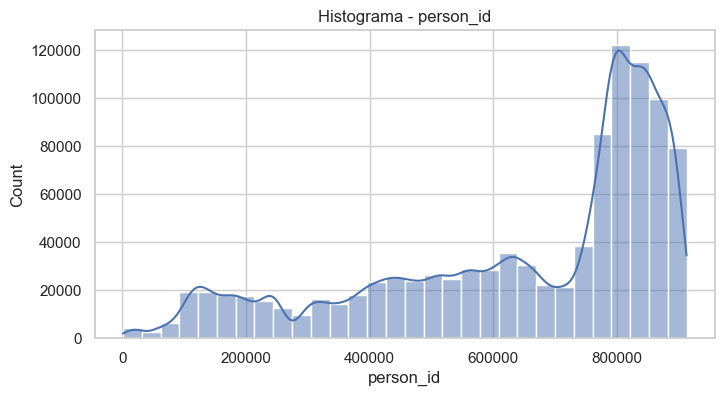

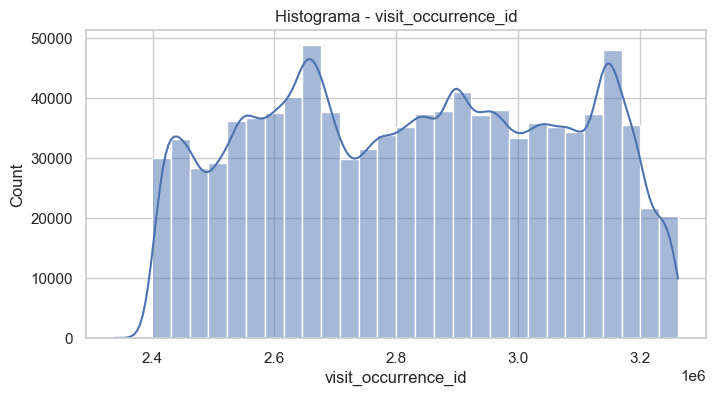

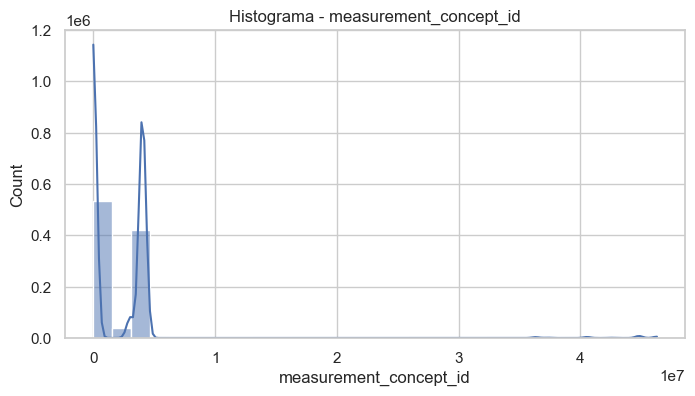

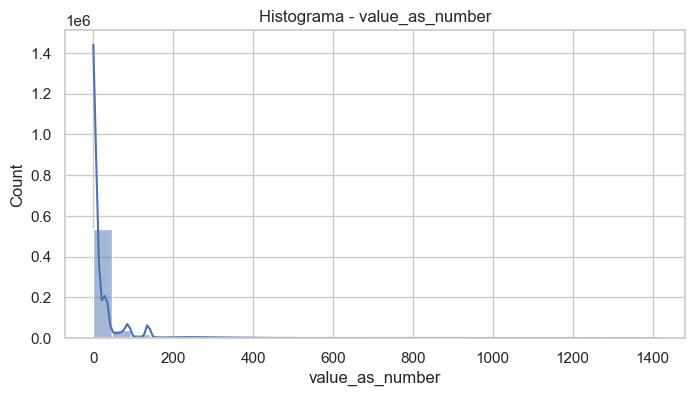

In [36]:
histogramas(measurement)

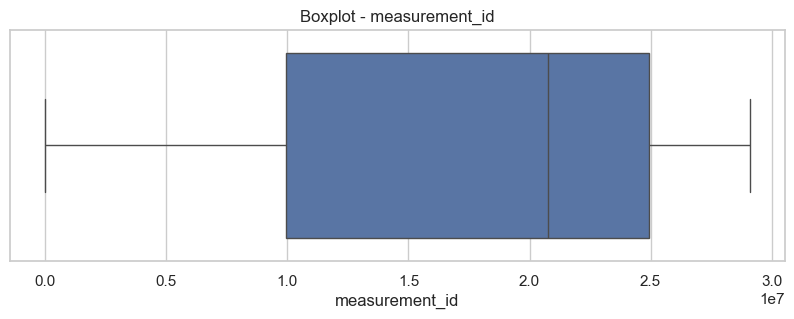

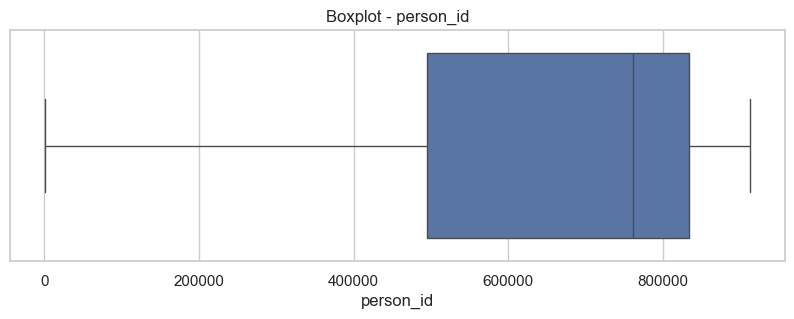

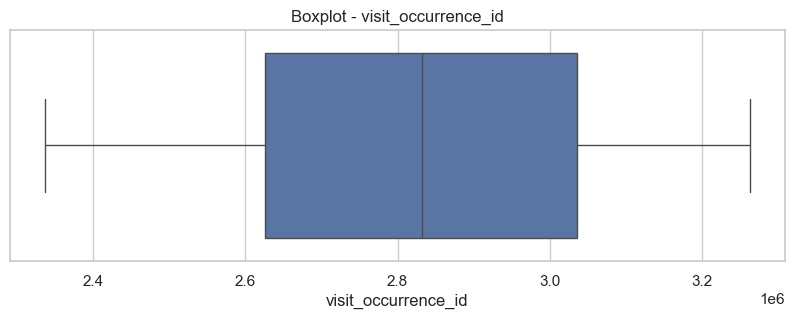

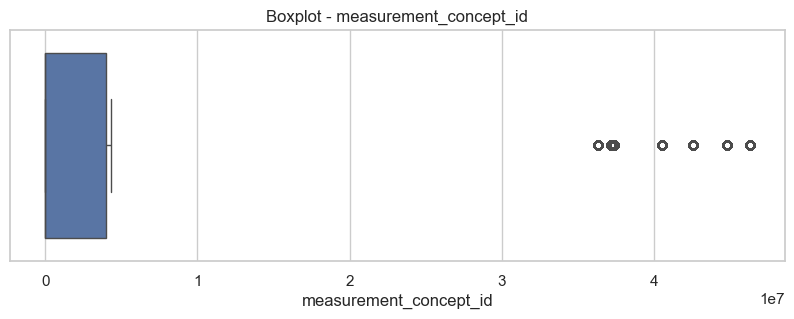

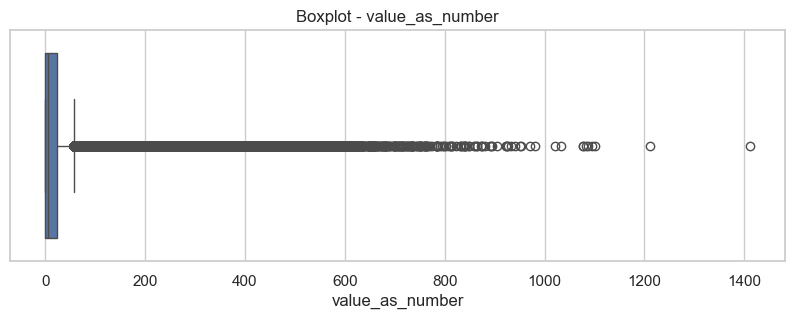

In [37]:
boxplots(measurement)

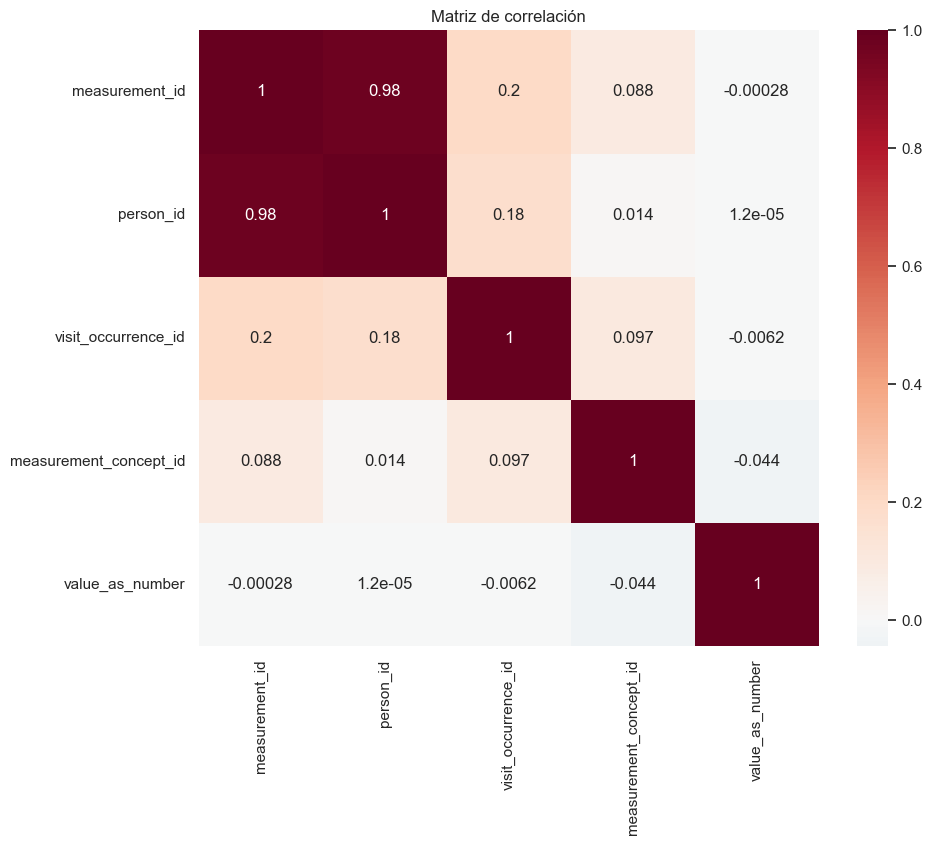

In [38]:
correlaciones(measurement)

## 1.5 visit_occurrence.csv



- visit_occurrence_id: Identificador único de cada visita o encuentro clínico del paciente.
- person_id: Identificador del paciente asociado a la visita.
- visit_concept_id: Identificador estandarizado del tipo de visita (urgencias, hospitalización, consulta, etc.).
- visit_start_datetime: Fecha y hora de inicio de la visita hospitalaria.
- visit_end_datetime: Fecha y hora de finalización de la visita hospitalaria.
- visit_type_concept_id: Identificador que describe el origen o tipo de registro de la visita.
- provider_id: Identificador del profesional de salud asociado a la visita.

In [39]:
visit_ocurrence = cargar_csv(
    "visit_occurrence.csv"
)

In [40]:
analizar_tabla(visit_ocurrence, "visit_occurrence")

TABLA: visit_occurrence

Filas: 1,706,001
Columnas: 6
Memoria: 273.33 MB

Duplicados: 0

Top faltantes:


,nulos,pct_nulos
visit_occurrence_id,0,0.0
person_id,0,0.0
visit_concept_id,0,0.0
visit_start_datetime,0,0.0
visit_end_datetime,0,0.0
provider_id,0,0.0



Resumen estadístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
visit_occurrence_id,1706001.0,NaN,NaN,NaN,1962777.092189,909991.805942,128513.0,1083747.0,2409349.0,2835849.0,3262349.0
person_id,1706001.0,NaN,NaN,NaN,651130.62876,229949.670094,1146.0,538433.0,746441.0,817668.0,912205.0
visit_concept_id,1706001.0,NaN,NaN,NaN,406446.990451,384523.334883,0.0,9203.0,581479.0,581479.0,3045729.0
visit_start_datetime,1706001,420853,2025-06-26 14:00:00,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit_end_datetime,1706001,420853,2025-06-26 14:00:00,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
provider_id,1706001.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


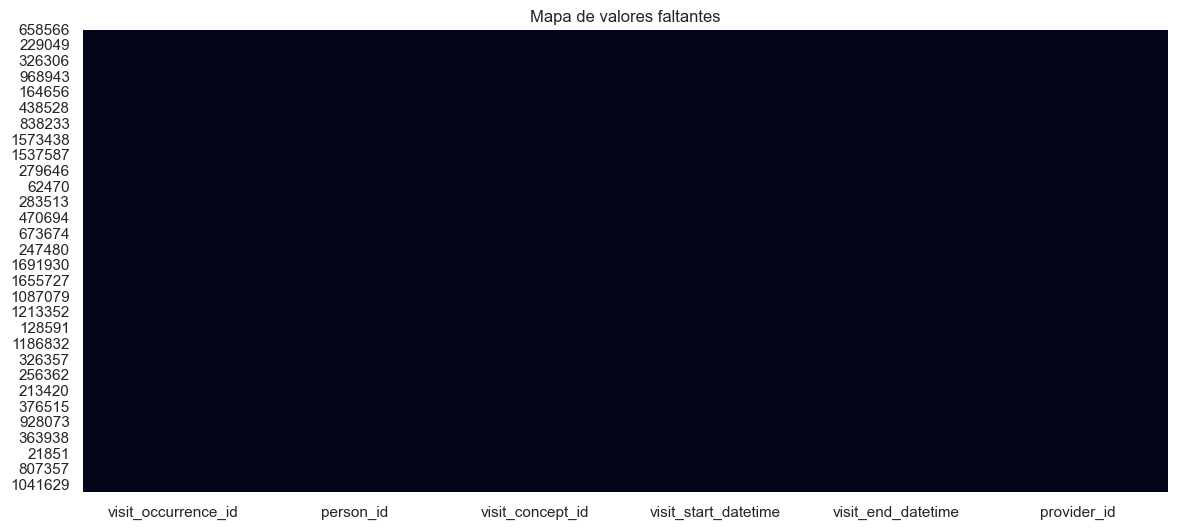

In [41]:
heatmap_nulos(visit_ocurrence)

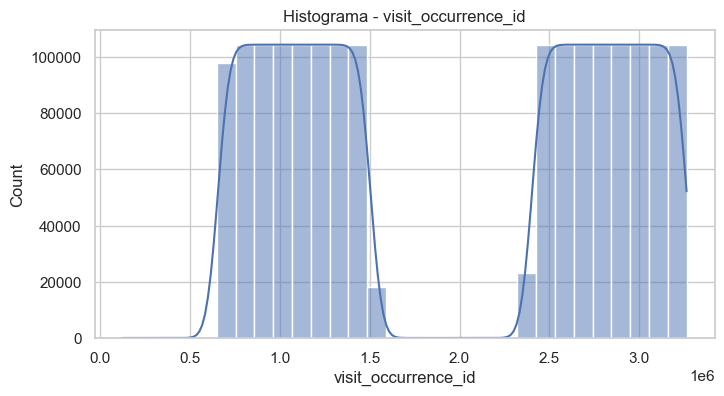

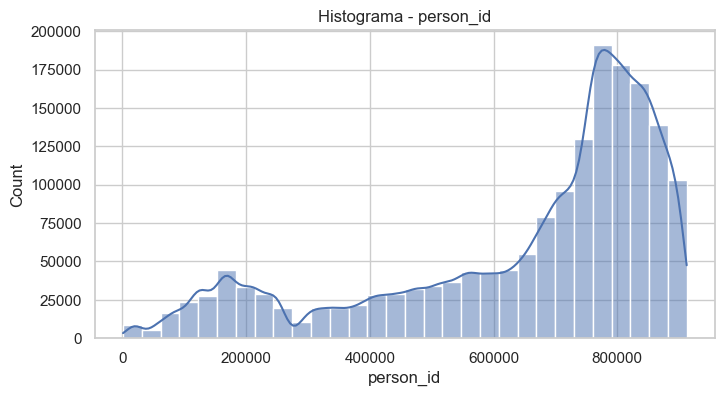

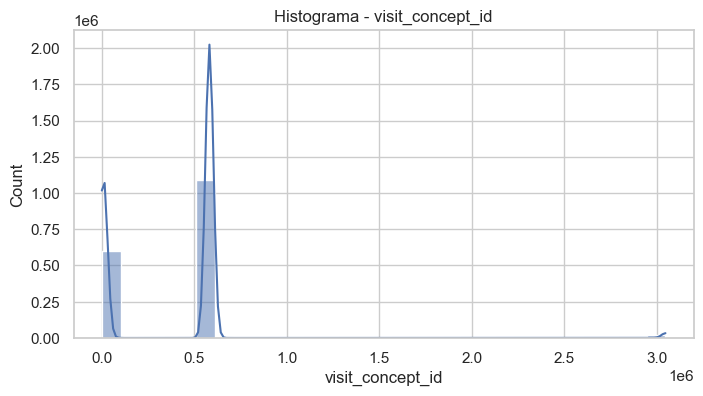

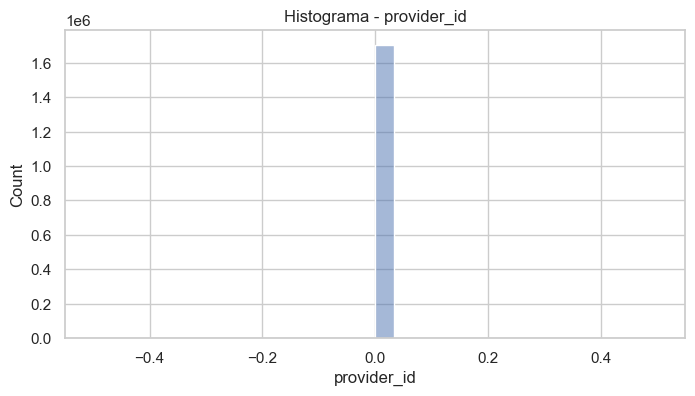

In [42]:
histogramas(visit_ocurrence)

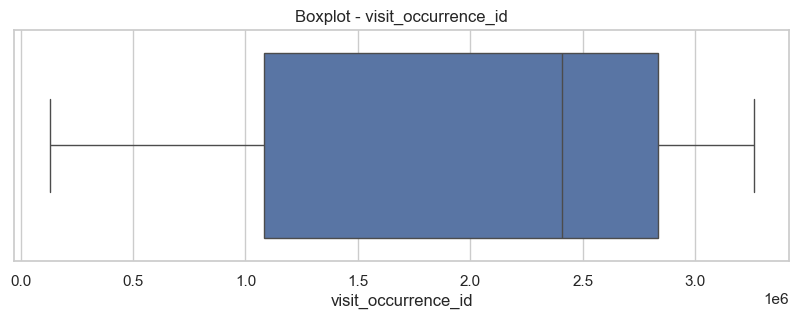

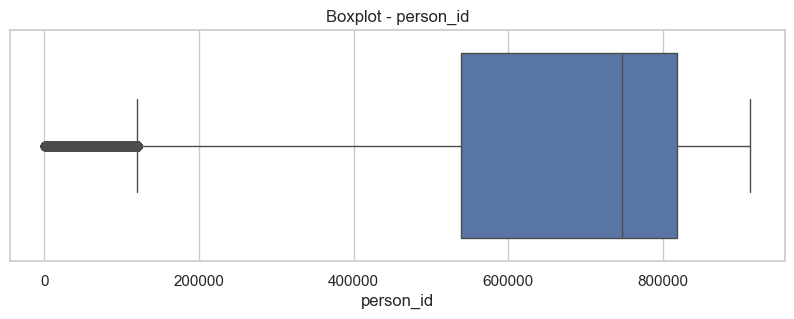

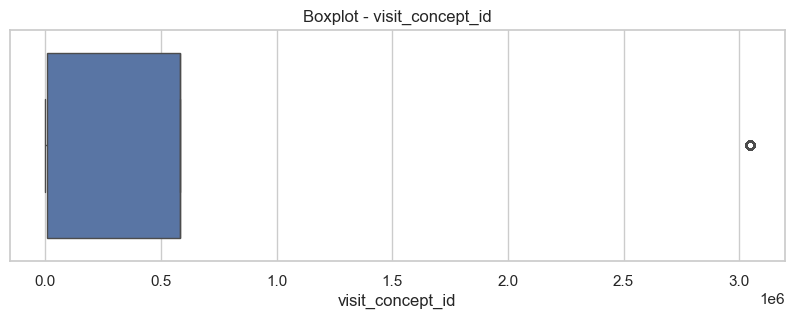

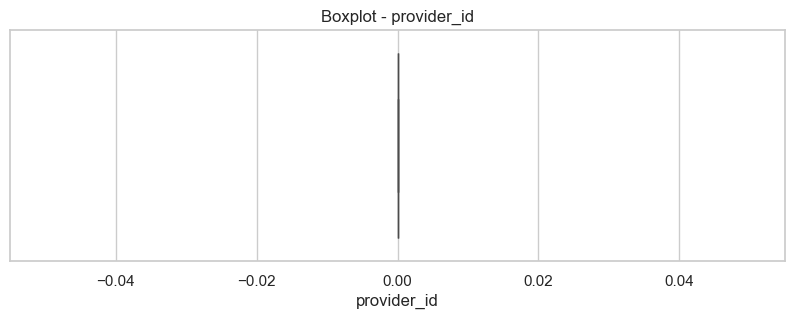

In [43]:
boxplots(visit_ocurrence)

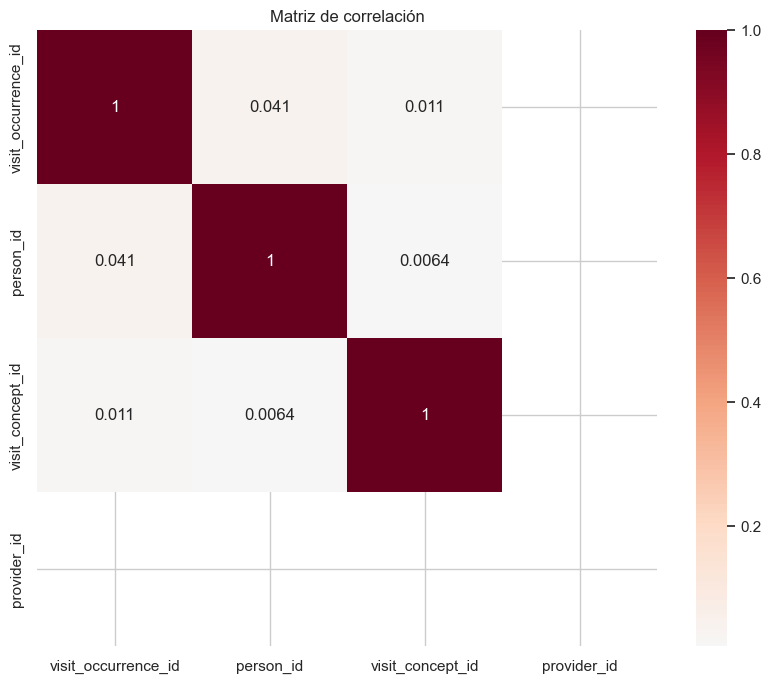

In [44]:
correlaciones(visit_ocurrence)

## 1.6 visit_detail.csv 


- visit_detail_id: Identificador único de cada detalle o microproceso dentro de una visita hospitalaria.
- visit_occurrence_id: Identificador de la visita principal asociada al detalle registrado.
- visit_detail_concept_id: Identificador estandarizado del tipo de etapa o subproceso clínico dentro de la visita.
- visit_detail_start_datetime: Fecha y hora de inicio del subproceso o etapa hospitalaria.
- visit_detail_end_datetime: Fecha y hora de finalización del subproceso o etapa hospitalaria.
- provider_id: Identificador del profesional asociado al subproceso registrado.

In [45]:
visit_detail = cargar_csv(
    "visit_detail.csv"
)

In [46]:
analizar_tabla(visit_detail, "visit_detail")

TABLA: visit_detail

Filas: 3,281,613
Columnas: 6
Memoria: 540.68 MB

Duplicados: 0

Top faltantes:


,nulos,pct_nulos
visit_detail_id,0,0.0
visit_occurrence_id,0,0.0
visit_detail_concept_id,0,0.0
visit_detail_start_datetime,0,0.0
visit_detail_end_datetime,0,0.0
provider_id,0,0.0



Resumen estadístico:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
visit_detail_id,3281613.0,NaN,NaN,NaN,4534683.783157,2711983.258913,1.0,2463041.0,4210328.0,7252837.0,9344195.0
visit_occurrence_id,3281613.0,NaN,NaN,NaN,2273763.059533,839979.804868,128513.0,1330626.0,2631351.0,2922656.0,3262349.0
visit_detail_concept_id,3281613.0,NaN,NaN,NaN,1343786.038617,1268807.811331,9201.0,581479.0,581479.0,3045729.0,3045729.0
visit_detail_start_datetime,3281613,855998,2025-06-26 14:00:00,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit_detail_end_datetime,3281613,1027984,2026-07-18 05:42:56.741644,1203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
provider_id,3281613.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


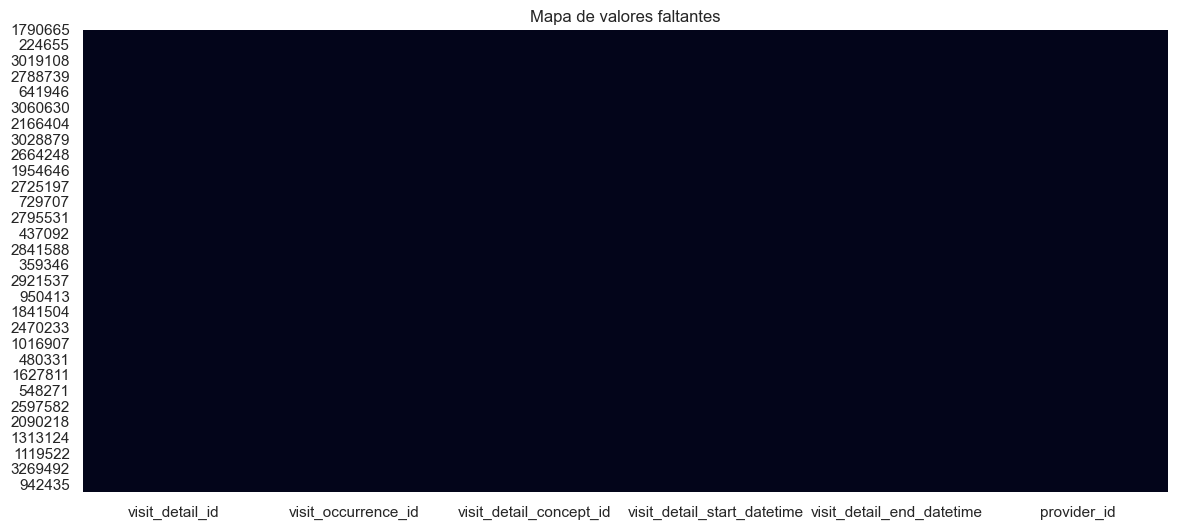

In [47]:
heatmap_nulos(visit_detail)

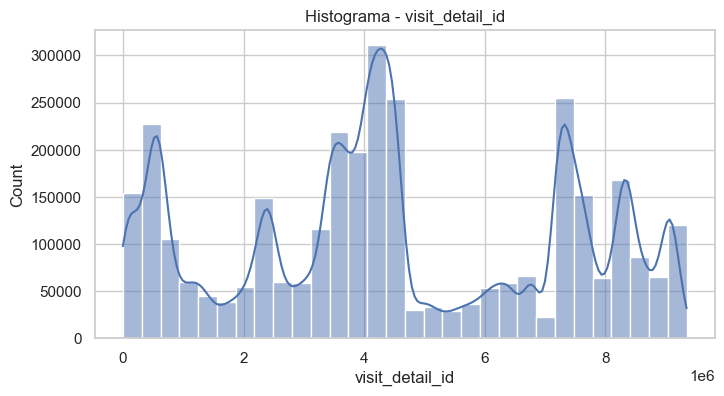

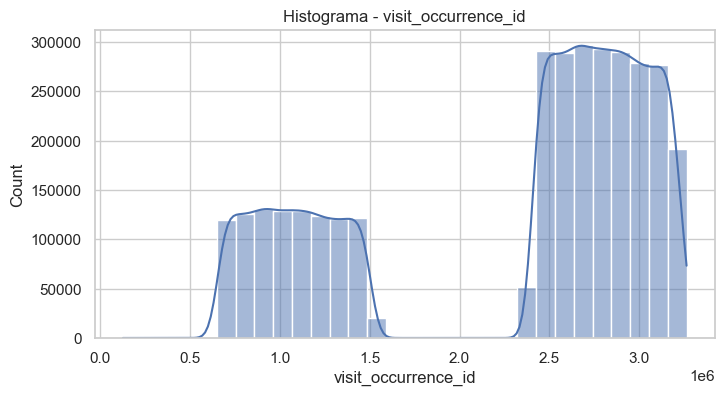

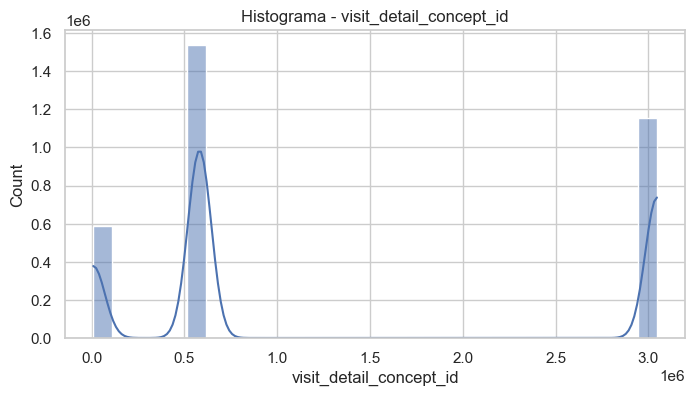

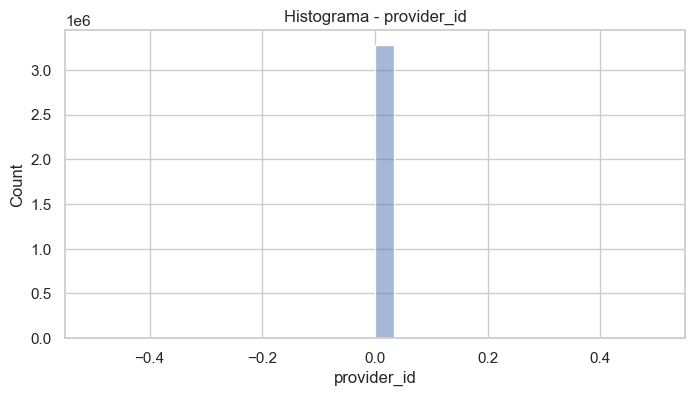

In [48]:
histogramas(visit_detail)

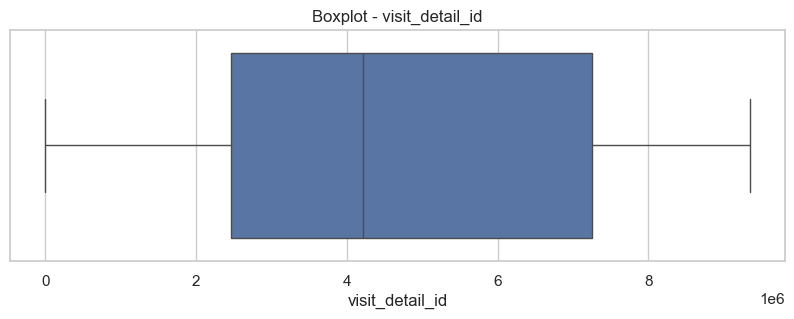

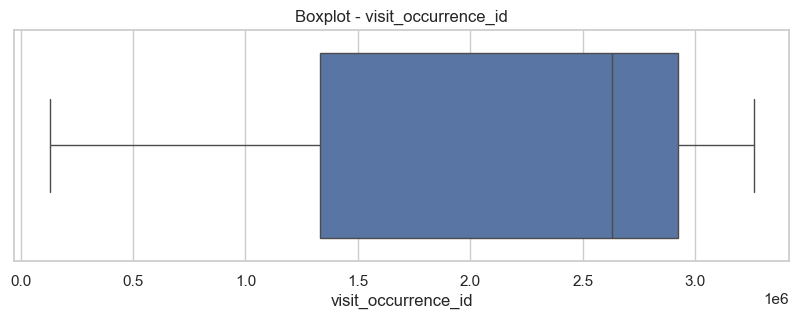

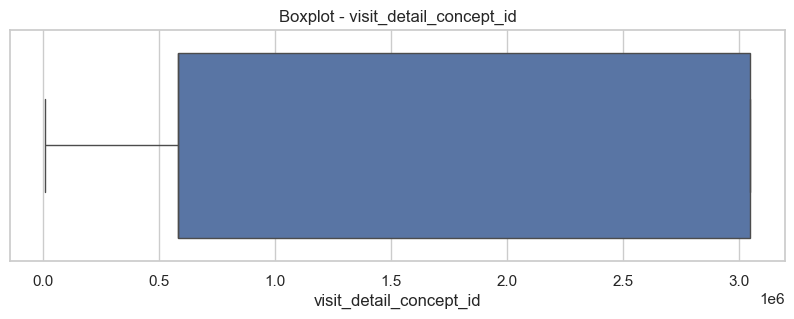

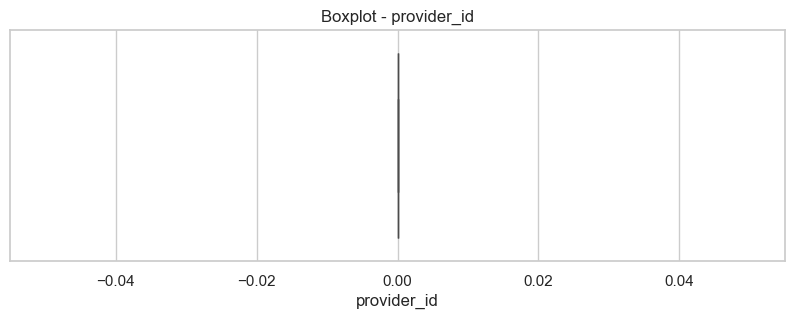

In [49]:
boxplots(visit_detail)

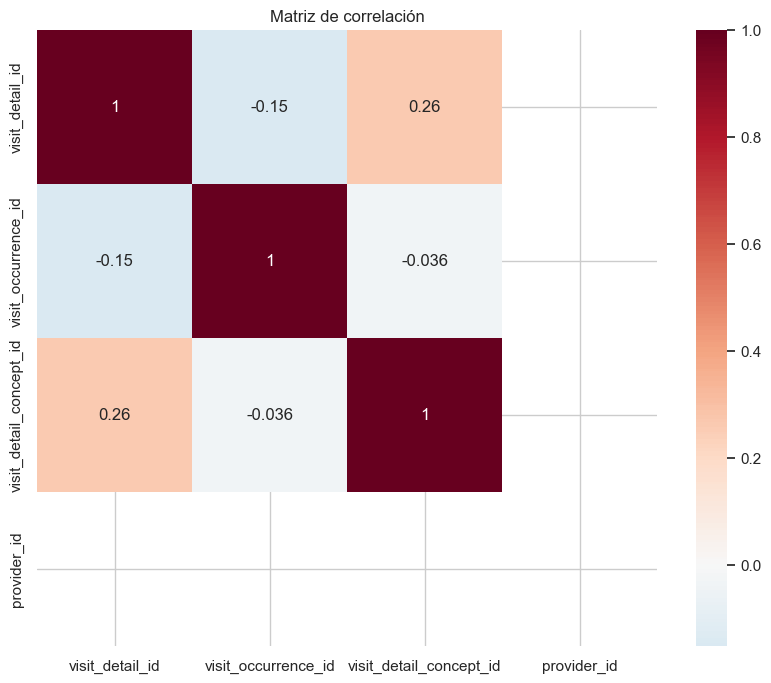

In [50]:
correlaciones(visit_detail)

# **2. Modelo Relacional de los Datos**

# **3. Ingenieria de Variables**